# Coherent extended source coupilng into VLT-fed fibre

**Interpretation:** Pupil and focal *overlap integrals* must match to numerical precision for the **same** field under a unitary FFT. Linear convolution on a finite window, a coarse phase-tilt sum, and a periodic FFT model are different numerical approximations and need not be identical until sampling/window convergence is established.

In [19]:
# Standard and scientific packages
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.signal import fftconvolve
from astropy.modeling.models import Sersic2D
from tqdm.auto import tqdm

# Keep your existing local package and its mode definitions.
src_path = Path('/Users/tliu/oh_suppression/codes/src')
if src_path.exists() and str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.dpi': 110,
})

SAVE_FIGURES = False
FIGURE_DIR = Path('coherent_galaxy_figures')

def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, dpi=220, bbox_inches='tight')
    plt.show()

In [20]:
from oh_suppression.fibre_modes import * 
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import * 

## 2. Define physical parameters and **one** common cooridinate system

In [21]:
# Telescope and fibre
lam0 = 1.5e-6                         # Wavelength [m]
NA = 0.1                              # Fibre numerical aperture
F_focus = 49.9                        # Coudé focal ratio before demagnification
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / F_focus
D_M1 = 8.0                            # Primary mirror diameter [m]
D_obstruction = 1.0                   # Central obstruction diameter [m]
alpha_vlt = D_obstruction / D_M1
rad_to_arcsec = (180 / np.pi) * 3600

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)
plate_scale_demag = plate_scale_coude / Magnification
f_eff = rad_to_arcsec / plate_scale_demag
lambda_D_arcsec = (lam0 / D_M1) * rad_to_arcsec

# CANDELS/GOODS-S compact Sérsic example
n_sersic = 3.335
Re_arcsec = 0.101
q_param = 0.514
PA_deg = -88.7
ellip = 1 - q_param
model_cent = Sersic2D(
    amplitude=1, r_eff=Re_arcsec, n=n_sersic,
    x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg)
)

# Fixed focal grid; do not redefine x/y elsewhere.
r_max = 125e-6                       # Computational half-width [m]; NOT a physical stop
n_grid = 1000                         # Even: zero-coordinate at index n_grid//2
dx = 2 * r_max / n_grid
x_1d = (np.arange(n_grid) - n_grid // 2) * dx
y_1d = x_1d.copy()
x, y = np.meshgrid(x_1d, y_1d)
x_arcsec, y_arcsec = x * plate_scale_demag, y * plate_scale_demag
QX, QY = x_arcsec / lambda_D_arcsec, y_arcsec / lambda_D_arcsec
angular_extent = r_max * plate_scale_demag

# Matched Fourier-conjugate pupil coordinates
p_1d = np.fft.fftshift(np.fft.fftfreq(n_grid, d=dx)) * lam0 * f_eff
PX, PY = np.meshgrid(p_1d, p_1d)
R_pupil = np.hypot(PX, PY)
pupil_mask = (R_pupil <= D_M1/2) & (R_pupil >= D_obstruction/2)
E_base_pupil = pupil_mask.astype(complex)
E_base_pupil /= np.linalg.norm(E_base_pupil)

print(f'Effective focal length: {f_eff:.4f} m')
print(f'Angular field half-width: {angular_extent:.4f} arcsec = {angular_extent/lambda_D_arcsec:.2f} λ/D')
print(f'Focal pixel spacing: {dx*1e6:.4f} µm = {(QX[0,1]-QX[0,0]):.5f} λ/D')
print(f'Pupil spacing: {p_1d[1]-p_1d[0]:.4f} m')
print(f'Telescope pupil pixels: {pupil_mask.sum():,}')

Effective focal length: 39.7995 m
Angular field half-width: 0.6478 arcsec = 16.75 λ/D
Focal pixel spacing: 0.2500 µm = 0.03350 λ/D
Pupil spacing: 0.2388 m
Telescope pupil pixels: 864


## 3. Source Brigtness: Gaussian and Sersic profile with the same normalisation

In [22]:
# Both profiles are evaluated directly at exactly the same angular pixels.
# No subpixel brightness averaging or arbitrary factors of five.

source_sigma = 1.0                     # Gaussian σ [λ/D]
I_gaussian = np.exp(-(QX**2 + QY**2) / (2 * source_sigma**2))
I_sersic = model_cent(x_arcsec, y_arcsec)

# Each source array is a finite-window, centre-sampled brightness model.
# Normalising the brightness before sqrt() matches the source-field treatment.
def normalise_intensity(I): 
    """
    Normalise a 2D intensity array to unit total flux.
    """
    if not np.all(np.isfinite(I)) or np.any(I < 0) or np.sum(I) <= 0:
        raise ValueError('The sampled source intensity must be finite and nonnegative.')
    I = np.array(I, dtype=float)
    return I / np.sum(I)

In [23]:
I_sersic.shape

(1000, 1000)

In [24]:
brightness = {
    'Gaussian': normalise_intensity(I_gaussian),
    'Sérsic': normalise_intensity(I_sersic),
}

# Flat phase: hypothetically 100% spatiallycoherent sources, no atmospheric turbulence, no AO residuals.
# name is the key for the source brightness model, e.g., "Gaussian" or "Sérsic".
E_source = {name: np.sqrt(I).astype(complex) for name, I in brightness.items()} # complex type for later field propagation

for name, I in brightness.items(): 
    print(f'{name:<9}: sum(I)={I.sum():.8f}, max-pixel fraction={100*I.max():.3f}%')

Gaussian : sum(I)=1.00000000, max-pixel fraction=0.018%
Sérsic   : sum(I)=1.00000000, max-pixel fraction=0.897%


The brightest pixel in the sersic profile contains 0.9 percent of the light

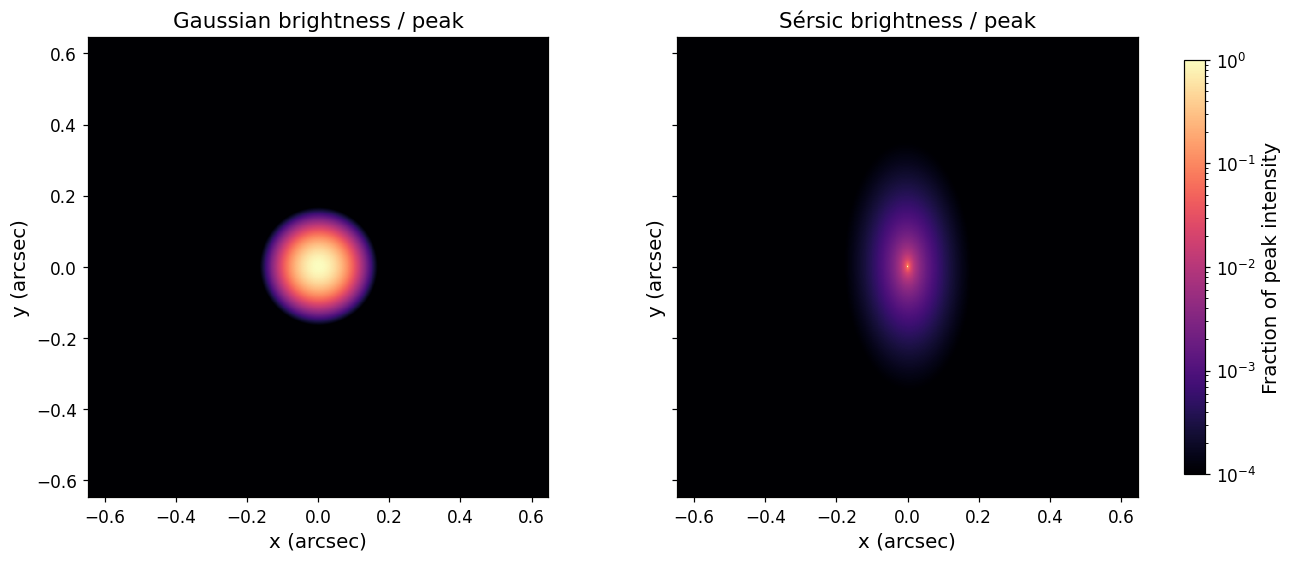

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True,)

for ax, (name, I) in zip(axes, brightness.items()):
    im = ax.imshow(
        I / I.max(),
        origin="lower",
        cmap="magma",
        extent=[
            x_arcsec.min(), x_arcsec.max(),
            y_arcsec.min(), y_arcsec.max(),
        ],
        norm=LogNorm(vmin=1e-4, vmax=1),
        interpolation="nearest",
    )

    ax.set(
        title=f"{name} brightness / peak",
        xlabel="x (arcsec)",
        ylabel="y (arcsec)",
    )
    ax.set_aspect("equal")

fig.colorbar(im,ax=axes, label="Fraction of peak intensity", shrink=0.9, pad=0.04, fraction=0.05)

### Angular sampling diagnostic — why the Sérsic differs more strongly

The **same** Sérsic function can give very different *normalised discrete* source distributions when sampled at different grid spacings. This is not a change in the analytic galaxy; it is a numerical quadrature error. In particular, the direct 31×31 centre sample over ±0.648 arcsec has a grid separation of ~1.12 λ/D. The central Sérsic cusp is represented by a single very bright sample.

In [26]:
def sample_sersic_grid(source_N, source_halfwidth, sersic_model=model_cent):
    """
    Sample a Sérsic source at the focal-plane pixels, without any convolution or interpolation.
    We do this to do point sampling to match the Gaussian source sampling grid. 

    Parameters: 
    source_N : int
        Number of pixels along one axis of the square source grid.
    source_halfwidth : float
        Half-width of the source grid in arcseconds.
    sersic_model : astropy.modeling.models.Sersic2D
        The Sérsic model to sample.
    
    Returns
    -------
    qx : numpy.ndarray
        The x-coordinates of the sampled points.
    qy : numpy.ndarray
        The y-coordinates of the sampled points.
    I : numpy.ndarray
        The sampled Sérsic intensity, normalised to unit total flux.
    """
    q = np.linspace(-source_halfwidth, source_halfwidth, source_N)
    qx, qy = np.meshgrid(q, q)
    I = sersic_model(qx * lambda_D_arcsec, qy * lambda_D_arcsec)

    return qx, qy, normalise_intensity(I)

 Angular N   Grid spacing [λ/D]    Brightest pixel [%]
        31              1.11671                92.8275
        51              0.67003                80.6976
       101              0.33501                49.0502
       201              0.16751                18.8089
      1000              0.03350                 0.8972


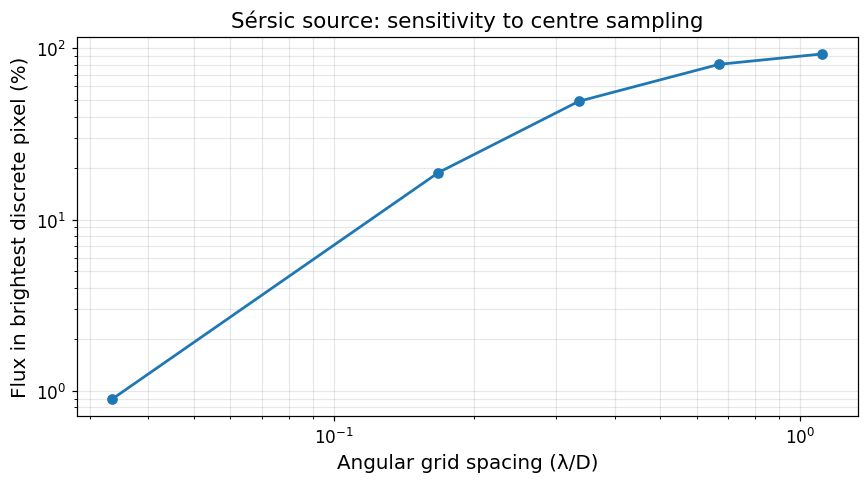

In [27]:
source_halfwidth_sersic = angular_extent / lambda_D_arcsec
sampling_sizes = [31, 51, 101, 201, n_grid]
sampling_rows = []
for samples in sampling_sizes:
    if samples == n_grid:
        I = brightness['Sérsic']  # Same FFT-centred array as the focal calculation
        dq = QX[0,1] - QX[0,0]
    else:
        _, _, I = sample_sersic_grid(samples, source_halfwidth_sersic)
        dq = 2 * source_halfwidth_sersic / (samples - 1)
    sampling_rows.append((samples, dq, 100 * I.max()))
# Angular N is the number of pixels along one axis of the square source grid.
# Grid spacing is the angular separation between adjacent pixels in units of λ/D.
# Brightest pixel is the maximum pixel value in the sampled intensity, expressed 
# as a percentage of the total flux.
print(f'{"Angular N":>10} {"Grid spacing [λ/D]":>20} {"Brightest pixel [%]":>22}')
for N, dq, peak in sampling_rows:
    print(f'{N:10d} {dq:20.5f} {peak:22.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog([row[1] for row in sampling_rows], [row[2] for row in sampling_rows],
          marker='o', lw=1.8)
ax.set(xlabel='Angular grid spacing (λ/D)', ylabel='Flux in brightest discrete pixel (%)',
       title='Sérsic source: sensitivity to centre sampling')
ax.grid(True, which='both', alpha=0.3)
finish_figure(fig, '02_sersic_sampling.png')

If the grid spacing is too small, the brightest pixel will be majority of the brightness of the entire field. 

## 4. Fourier conventions and telescope PSF

In [28]:
def fft2c(field):
    """
    Centred, unitary forward 2-D FFT: pupil field -> fibre input plane.
    Transforms a 2D field from the pupil plane to the fibre input plane using a centred, 
    unitary forward 2-D FFT.
    """
    foward_fft = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(field), norm='ortho'))
    return foward_fft


def ifft2c(field):
    """
    Centred, unitary inverse 2-D FFT: fibre mode field -> pupil.
    Transforms a 2D field from the fibre input plane to the pupil plane using a centred,
    unitary inverse 2-D FFT.
    """
    inverse_fft = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(field), norm='ortho'))
    return inverse_fft


def linear_convolution_centred(E_source, E_psf):
    """
    Full linear complex-field convolution, cropped to the original
    FFT-centred grid. Explicit crop avoids the even-N 1-pixel 'same' offset.

    The complete linear convolution extends outside the returned grid.
    That finite-window loss is diagnosed independently below.
    """
    # assert means that the shapes of the source and PSF arrays must be the same; 
    # if not, an AssertionError will be raised.
    assert E_source.shape == E_psf.shape
    n_y, n_x = E_source.shape # dimensions of the source field
    # Convolve the source field with the PSF using FFT-based convolution. 
    full = fftconvolve(E_source, E_psf, mode='full') # note 'full' mode returns the complete convolution, which is larger than the original arrays
    # Crop the full convolution result to the original source field size, centered around the middle of the full array.
    cy, cx = n_y // 2, n_x // 2
    return full[cy:cy+n_y, cx:cx+n_x]


# The exact PSF corresponding to the sampled VLT pupil mask.
# Use the *complex amplitude* field, not an intensity PSF.
E_psf_fft = fft2c(E_base_pupil)

assert np.isclose(np.vdot(E_psf_fft, E_psf_fft).real, 1.0, atol=1e-12)
print('On-axis FFT PSF power:', np.vdot(E_psf_fft, E_psf_fft).real)

On-axis FFT PSF power: 1.0000000000000004


### Optional check: original analytical PSF versus sampled-pupil PSF

The original notebook used `diffraction_limited_E_field_at_fibre_2d()` in the convolution, but a sampled annular pupil in the pupil-plane calculation. This optional check compares the **complex** PSFs directly; agreement is not guaranteed simply because they represent the same nominal aperture.


Analytic versus sampled-pupil PSF overlap: 0.98986670


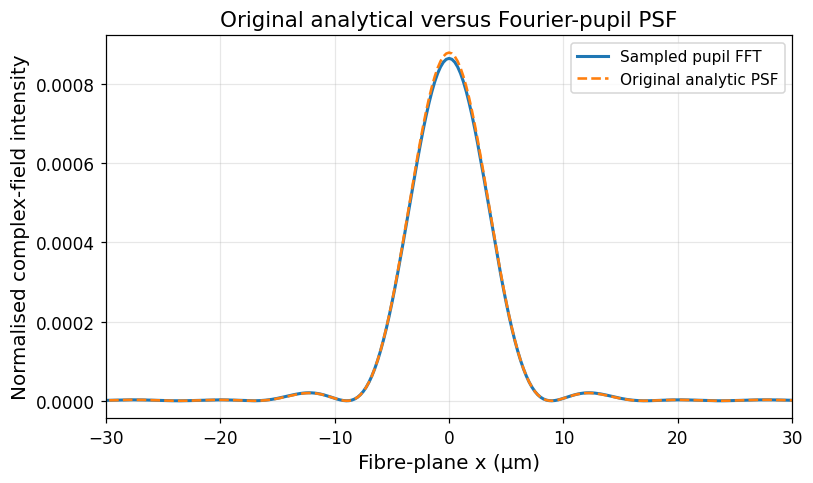

In [29]:
# Check if the complex psf from the sampled pupil matches the analytic diffraction-limited 
# PSF for the same telescope and fibre parameters.
try:
    from oh_suppression.image_plane_fields import diffraction_limited_E_field_at_fibre_2d
    E_psf_analytic, _ = diffraction_limited_E_field_at_fibre_2d(
        x, y, lam0, F_fibre, alpha=alpha_vlt, E_S=1.0, decentre=None
    )
    E_psf_analytic = np.asarray(E_psf_analytic, dtype=complex)
    E_psf_analytic /= np.linalg.norm(E_psf_analytic)

    # The absolute squared field overlap ignores an arbitrary global phase.
    match = np.vdot(E_psf_fft, E_psf_analytic)
    print(f"Analytic versus sampled-pupil PSF overlap: {abs(match)**2:.8f}")

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    mid = n_grid // 2
    ax.plot(x_1d*1e6, abs(E_psf_fft[mid])**2,
            label='Sampled pupil FFT', linewidth=2)
    ax.plot(x_1d*1e6, abs(E_psf_analytic[mid])**2,
            '--', label='Original analytic PSF', linewidth=1.7)
    ax.set(xlim=(-30, 30), xlabel='Fibre-plane x (µm)',
           ylabel='Normalised complex-field intensity',
           title='Original analytical versus Fourier-pupil PSF')
    ax.grid(alpha=0.3)
    ax.legend()
    finish_figure(fig, 'psf_model_comparison.png')
except (ImportError, AttributeError) as error:
    print('Optional analytic PSF comparison unavailable:', error)



### Optional verification: Linear versus circular convolution

The focal-plane convolution and pupil-plane FFT are mathematically equivalent descriptions of coherent image formation, but their finite-grid implementations use different boundary conditions.

**Linear convolution**

$$
E_{\mathrm{linear}}
=
E_{\mathrm{source}} * E_{\mathrm{PSF}}
$$

The full linear convolution is calculated with zero padding, then cropped to the original focal-plane grid.

**Circular convolution**

$$
E_{\mathrm{periodic}}
=
\mathrm{FFT}_c
\left[
P \cdot N\,\mathrm{IFFT}_c(E_{\mathrm{source}})
\right]
$$

The FFT operates on the original finite grid, implicitly treating the field as periodic.

**Verification:** Compare the resulting focal-plane electric fields, their total powers, and their spatial differences to investigate the influence of computational boundaries.


In [30]:
# ============================================================
# OPTIONAL VERIFICATION: LINEAR VS CIRCULAR CONVOLUTION
# ============================================================
#
# Both calculations use exactly the same fine-grid source
# electric field and complex PSF.
#
# 1. Periodic FFT:
#    Construct the coherent pupil field using an inverse FFT
#    of the source, then propagate to the focal plane.
#
# 2. Linear convolution:
#    Convolve the source electric field with the complex PSF
#    using zero padding, then crop to the original grid.
#
# The comparison investigates finite-grid boundary effects.
# ============================================================


# ------------------------------------------------------------
# 1. Periodic FFT construction
# ------------------------------------------------------------

# The factor n_grid accounts for the unitary FFT normalisation
# on a square n_grid × n_grid array.

E_pupil_periodic = {
    name: E_base_pupil * (n_grid * ifft2c(S))
    for name, S in E_source.items()
}

# Propagate the coherent pupil field into the focal plane.
E_focal_periodic = {
    name: fft2c(E_pupil)
    for name, E_pupil in E_pupil_periodic.items()
}


# ------------------------------------------------------------
# 2. Linear convolution construction
# ------------------------------------------------------------

E_focal_linear = {
    name: linear_convolution_centred(S, E_psf_fft)
    for name, S in E_source.items()
}


# ------------------------------------------------------------
# 3. Quantify differences between the two constructions
# ------------------------------------------------------------

boundary_diagnostics = {}

for name in E_source:

    E_periodic = E_focal_periodic[name]
    E_linear = E_focal_linear[name]

    # Relative L2 difference between complex electric fields.
    relative_field_difference = (
        np.linalg.norm(E_linear - E_periodic)
        / np.linalg.norm(E_periodic)
    )

    # Compare total electric-field powers on the returned grid.
    power_periodic = np.vdot(
        E_periodic, E_periodic
    ).real

    power_linear = np.vdot(
        E_linear, E_linear
    ).real

    linear_to_periodic_power_ratio = (
        power_linear / power_periodic
    )

    boundary_diagnostics[name] = {
        "relative_field_difference": relative_field_difference,
        "power_periodic": power_periodic,
        "power_linear": power_linear,
        "power_ratio": linear_to_periodic_power_ratio,
    }

    print(
        f"{name:<9}: "
        f"Relative field difference = {relative_field_difference:.4%}, "
        f"Linear / periodic power = {linear_to_periodic_power_ratio:.5f}"
    )

Gaussian : Relative field difference = 5.3000%, Linear / periodic power = 0.98928
Sérsic   : Relative field difference = 11.9758%, Linear / periodic power = 0.97766


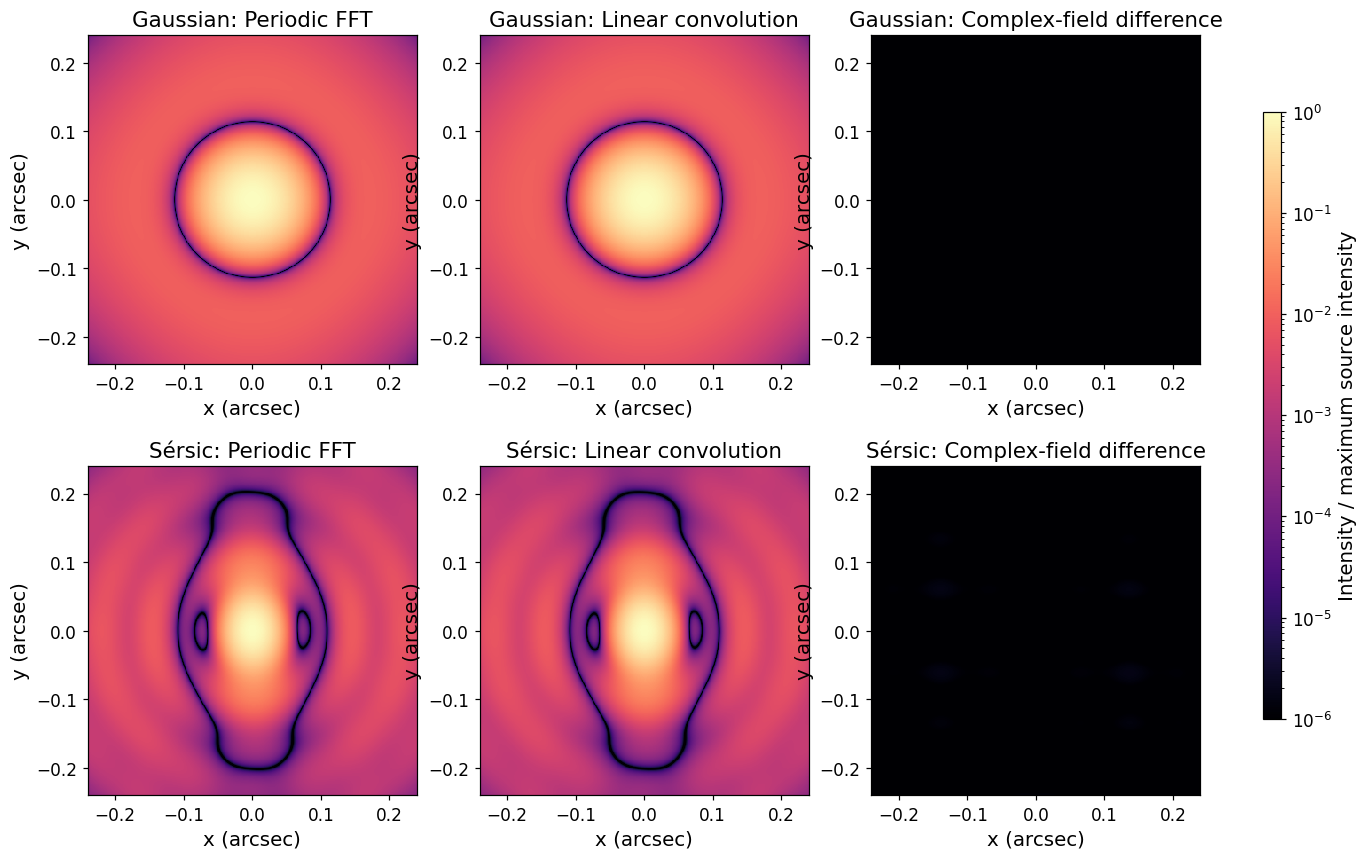

In [31]:
# ============================================================
# OPTIONAL FIGURE: CONVOLUTION BOUNDARY COMPARISON
# ============================================================

fig = plt.figure(
    figsize=(14, 9),
    constrained_layout=True
)

grid = fig.add_gridspec(
    2, 4,
    width_ratios=[1, 1, 1, 0.055],
    wspace=0.25,
    hspace=0.30
)

axes = np.array([
    [fig.add_subplot(grid[row, col]) for col in range(3)]
    for row in range(2)
])

# Plot Gaussian and Sérsic coherent source fields.
for row, name in enumerate(E_source):

    E_periodic = E_focal_periodic[name]
    E_linear = E_focal_linear[name]

    # Intensity distributions.
    I_periodic = np.abs(E_periodic)**2
    I_linear = np.abs(E_linear)**2

    # Squared magnitude of the complex-field difference.
    I_difference = np.abs(
        E_linear - E_periodic
    )**2

    # Use the same normalisation for all three columns
    # within each source.
    max_intensity = max(
        I_periodic.max(),
        I_linear.max()
    )

    plot_data = [
        (I_periodic, "Periodic FFT"),
        (I_linear, "Linear convolution"),
        (I_difference, "Complex-field difference")
    ]

    for col, (data, label) in enumerate(plot_data):

        ax = axes[row, col]

        im = ax.imshow(
            data / max_intensity,
            origin="lower",
            cmap="magma",
            extent=[
                x_arcsec.min(), x_arcsec.max(),
                y_arcsec.min(), y_arcsec.max()
            ],
            norm=LogNorm(vmin=1e-6, vmax=1),
            interpolation="nearest"
        )

        ax.set(
            xlim=(-0.24, 0.24),
            ylim=(-0.24, 0.24),
            title=f"{name}: {label}",
            xlabel="x (arcsec)",
            ylabel="y (arcsec)"
        )

        ax.set_aspect("equal")


# ------------------------------------------------------------
# Shared colourbar
# ------------------------------------------------------------

cbar_subgrid = grid[:, 3].subgridspec(
    10, 1
)

cbar_ax = fig.add_subplot(
    cbar_subgrid[1:9]
)

fig.colorbar(
    im,
    cax=cbar_ax,
    label="Intensity / maximum source intensity"
)

plt.show()

## 5. Constructing the coherent galaxy field: focal convolution versus direct pupil phase tilts

**Method 1 — Focal-plane linear convolution:** convolve the source electric-field amplitude with the complex PSF, using full zero-padded linear convolution and cropping to the focal grid.

$$
E_{\mathrm{gal,focal}}=E_{\mathrm{source}}*E_{\mathrm{PSF}}
$$

**Method 2 — Direct pupil-plane phase-tilt summation:** independently sample the Gaussian or Sérsic intensity on angular coordinates $(QX,QY)$ and coherently sum the corresponding tilted pupil fields.

$$
E_{\mathrm{gal,pupil}}(u,v)=P(u,v)\sum_{ij}\sqrt{I_{ij}}\exp\!\left[\frac{2\pi i}{D_{M1}}(QX_{ij}u+QY_{ij}v)\right]
$$

Calculate Method 2 at both a **high-resolution** angular grid (`pupil_fine`) and an **original coarse** grid (`pupil_coarse`). The high-resolution calculation uses the **direct Sérsic/Gaussian brightness model**, not an inverse FFT of the focal-plane source array.

**Numerical check:** forward-FFT the directly constructed high-resolution pupil field, then calculate overlaps in both planes. These two overlaps should agree because they describe the same field. Boundary treatment can still make the focal-plane *linear convolution* differ from the FFT-propagated pupil field.


In [32]:
# Method 1 — focal-plane linear convolution, independent of QX/QY pupil construction.
E_focal_convolution = {
    name: linear_convolution_centred(S, E_psf_fft)
    for name, S in E_source.items()
}


### Method 2: directly sum source positions on the angular `QX`, `QY` grid

The same `prepare_gaussian_source_pupil` and `prepare_sersic_source_pupil` functions produce **coarse and fine** pupil fields. To avoid evaluating a separate million-pixel pupil field for every sky position, we exploit the separability of the phase tilt:

$$
E_{\mathrm{gal,pupil}}(u,v)=P(u,v)\sum_j e^{2\pi i vQY_j/D}\left(\sum_i \sqrt{I_{ji}}e^{2\pi i uQX_i/D}\right).
$$

This is still the **explicit angular phase-tilt sum**, evaluated as two matrix multiplications; no source-field FFT is used. The source sampling half-width is held fixed when changing `source_N`.


### Direct angular phase tilt source

In [33]:
def _source_pupil_from_intensity(
    QX, QY,
    I_source_sky,
    E_base_pupil,
    PX, PY,
    D_M1,
    batch_size=16
):
    """
    Precompute the coherent pupil electric field of an extended source
    by summing phase-tilted point-source fields in small batches.

    The individual point-source pupil fields are not stored in a
    large matrix. Instead, the angular positions and active pupil
    coordinates are retained for later incoherent coupling calculations.

    Parameters
    ----------
    QX, QY : 2D arrays
        Angular source coordinates in lambda/D units.

    I_source_sky : 2D array
        Source surface brightness distribution.

    E_base_pupil : 2D complex array
        On-axis point-source electric field at the telescope pupil.

    PX, PY : 2D arrays
        Physical telescope pupil coordinates [m].

    D_M1 : float
        Telescope primary mirror diameter [m].

    batch_size : int
        Number of angular source elements processed per batch.

    Returns
    -------
    source_data : dict
        Contains:
            QX, QY
            I_source_sky
            pupil_indices
            PX_active, PY_active
            E_base_active
            QX_flat, QY_flat
            E_point_pupil
            E_source_pupil_active
            E_source_pupil
            P_coherent_pupil

        E_point_pupil is None because individual point-source fields
        can be reconstructed in batches when needed.
    """

    # ========================================================
    # 1. Normalise the source brightness
    # ========================================================

    I_source_sky = np.asarray(
        I_source_sky,
        dtype=float
    )

    if (
        not np.all(np.isfinite(I_source_sky))
        or np.any(I_source_sky < 0)
        or np.sum(I_source_sky) <= 0
    ):
        raise ValueError("Source brightness must be finite and non-negative.")

    I_source_sky = (
        I_source_sky / np.sum(I_source_sky)
    )

    # ========================================================
    # 2. Extract nonzero telescope pupil pixels
    # ========================================================

    pupil_indices = np.flatnonzero(
        np.abs(E_base_pupil.ravel()) > 0
    )

    PX_active = PX.ravel()[pupil_indices]
    PY_active = PY.ravel()[pupil_indices]

    # Make a copy to avoid modifying the original pupil field.
    E_base_active = (
        E_base_pupil.ravel()[pupil_indices].copy()
    )

    # Normalise the on-axis point-source pupil field.
    E_base_active /= np.linalg.norm(E_base_active)

    # ========================================================
    # 3. Flatten the angular source coordinates
    # ========================================================

    QX_flat = QX.ravel()
    QY_flat = QY.ravel()

    # Coherent electric-field amplitudes are proportional
    # to the square root of the normalised brightness.
    coherent_weights = np.sqrt(
        I_source_sky.ravel()
    )

    # ========================================================
    # 4. Construct the coherent source pupil field
    # ========================================================

    E_source_pupil_active = np.zeros(
        pupil_indices.size,
        dtype=complex
    )

    # Process the source elements in small batches
    # rather than storing all point-source pupil fields.

    for first in range(0, QX_flat.size, batch_size):

        last = min(
            first + batch_size,
            QX_flat.size
        )

        # Geometrical phase tilt for each source position.
        tilt = np.exp(
            2j * np.pi / D_M1 * (
                QX_flat[first:last, None]
                * PX_active[None, :]
                +
                QY_flat[first:last, None]
                * PY_active[None, :]
            )
        )

        # Coherently sum the phase-tilted fields.
        #
        # Equivalent to:
        # E_point_pupil = tilt * E_base_active[None, :]
        # E_source += coherent_weights @ E_point_pupil
        #
        # Multiplying by E_base_active after the matrix
        # product avoids creating another large complex array.

        E_source_pupil_active += (
            coherent_weights[first:last] @ tilt
        ) * E_base_active

    # ========================================================
    # 5. Calculate total coherent incident pupil power
    # ========================================================

    P_coherent_pupil = np.vdot(
        E_source_pupil_active,
        E_source_pupil_active
    ).real

    # ========================================================
    # 6. Reconstruct the full coherent pupil field
    # ========================================================

    E_source_pupil = np.zeros_like(
        E_base_pupil,
        dtype=complex
    )

    E_source_pupil.ravel()[pupil_indices] = (
        E_source_pupil_active
    )

    # ========================================================
    # 7. Store precomputed source data
    # ========================================================

    source_data = {
        "QX": QX,
        "QY": QY,
        "I_source_sky": I_source_sky,

        "pupil_indices": pupil_indices,

        # Retained for later point-source field reconstruction.
        "PX_active": PX_active,
        "PY_active": PY_active,
        "E_base_active": E_base_active,
        "QX_flat": QX_flat,
        "QY_flat": QY_flat,
        "D_M1": D_M1,

        # Not stored to avoid excessive memory usage.
        "E_point_pupil": None,

        # Coherent source field.
        "E_source_pupil_active": E_source_pupil_active,
        "E_source_pupil": E_source_pupil,
        "P_coherent_pupil": P_coherent_pupil
    }

    return source_data

In [34]:
def incoherent_efficiency_pupil_modes(
    source_data,
    prepared_modes,
    E_base_pupil,
    PX, PY,
    D_M1,
    lam0,
    F_eff,
    a,
    integration_boundary="full",
    batch_size=16
):
    """
    Calculate incoherent extended-source coupling efficiency
    into every prepared fibre mode.

    Parameters
    ----------
    integration_boundary : str
        "full" : Include all sampled source positions.

        "core" : Include only source positions whose
                 geometrical image-plane radius is <= a.

    a : float
        Fibre core radius [m].

    F_eff : float
        Effective focal ratio at the fibre input.

    Returns
    -------
    eta_modes : 1D array
        Incoherent efficiency of each fibre mode.

    source_flux_fraction : float
        Fraction of the sampled source brightness within
        the selected integration boundary.
    """

    # ========================================================
    # 1. Extract active telescope pupil coordinates
    # ========================================================

    pupil_indices = source_data["pupil_indices"]

    PX_active = PX.ravel()[pupil_indices]
    PY_active = PY.ravel()[pupil_indices]

    E_base_active = (
        E_base_pupil.ravel()[pupil_indices].copy()
    )

    E_base_active /= np.linalg.norm(E_base_active)

    # ========================================================
    # 2. Source angular coordinates and brightness
    # ========================================================

    QX_flat = source_data["QX"].ravel()
    QY_flat = source_data["QY"].ravel()

    I_source_flat = source_data["I_source_sky"].ravel().copy()

    # ========================================================
    # 3. Apply the integration boundary
    # ========================================================

    if integration_boundary == "core":

        # Convert angular positions into geometrical
        # image-plane distances from the fibre centre [m].
        r_source = (
            F_eff * lam0
            * np.hypot(QX_flat, QY_flat)
        )

        core_mask = r_source <= a

        # Exclude source elements outside the fibre core.
        I_source_flat[~core_mask] = 0.0

    elif integration_boundary != "full":

        raise ValueError(
            "integration_boundary must be 'full' or 'core'."
        )

    # Fraction of the original sampled source brightness
    # retained within the integration boundary.
    source_flux_fraction = np.sum(I_source_flat)

    if source_flux_fraction <= 0:
        raise ValueError(
            "No source brightness falls within the boundary."
        )

    # Normalise to the brightness within the selected region.
    # This reproduces a weighted-average efficiency
    # whose denominator is the selected source flux.
    I_source_flat /= source_flux_fraction

    # ========================================================
    # 4. Prepare fibre modes in the pupil plane
    # ========================================================

    mode_fields = []
    mode_powers = []

    for mode in prepared_modes:

        E_mode_pupil = ifft2c(
            mode["E_mode"]
        )

        # Full mode power before restricting to pupil pixels.
        P_mode = np.vdot(
            E_mode_pupil,
            E_mode_pupil
        ).real

        mode_powers.append(P_mode)

        mode_fields.append(
            E_mode_pupil.ravel()[pupil_indices]
        )

    mode_fields = np.column_stack(mode_fields)
    mode_powers = np.asarray(mode_powers)

    eta_modes = np.zeros(len(prepared_modes))

    # ========================================================
    # 5. Calculate incoherent modal powers in batches
    # ========================================================

    for first in range(0, QX_flat.size, batch_size):

        last = min(
            first + batch_size,
            QX_flat.size
        )

        # Skip batches containing no selected source brightness.
        weights = I_source_flat[first:last]

        if not np.any(weights > 0):
            continue

        # Geometrical phase tilts of individual source elements.
        tilt = np.exp(
            2j * np.pi / D_M1 * (
                QX_flat[first:last, None] * PX_active[None, :]
                +
                QY_flat[first:last, None] * PY_active[None, :]
            )
        )

        E_point_pupil = (
            tilt * E_base_active[None, :]
        )

        # Point-source overlap with every fibre mode.
        amplitudes = (
            E_point_pupil @ np.conj(mode_fields)
        )

        # Incoherent intensity-weighted modal powers.
        eta_modes += np.sum(
            weights[:, None] * np.abs(amplitudes)**2,
            axis=0
        )

    # Each point-source pupil field has unit power.
    eta_modes /= mode_powers

    return eta_modes, source_flux_fraction

In [35]:

def prepare_gaussian_source_pupil(E_base_pupil, PX, PY, D_M1,
                                  source_N=21, source_sigma=1.0,
                                  source_halfwidth=4.0, batch_size=128):
    """Direct Gaussian brightness samples and phase-tilt pupil sum."""
    q = np.linspace(-source_halfwidth, source_halfwidth, source_N)
    QX_src, QY_src = np.meshgrid(q, q)
    I_source_sky = np.exp(-(QX_src**2 + QY_src**2)/(2*source_sigma**2))
    return _source_pupil_from_intensity(
        QX_src, QY_src, I_source_sky,
        E_base_pupil, PX, PY, D_M1, batch_size=batch_size
    )


def prepare_sersic_source_pupil(E_base_pupil, PX, PY, D_M1, lam0,
                                sersic_model, source_N=31,
                                source_halfwidth=4.0, batch_size=128):
    """
    Direct Sérsic brightness samples, **same procedure as Gaussian**.
    No pixel_subsamples argument. No 5×5 averaging or reweighting.
    The Sérsic model receives positions in arcseconds.
    """
    q = np.linspace(-source_halfwidth, source_halfwidth, source_N)
    QX_src, QY_src = np.meshgrid(q, q)
    lambda_D_arcsec_local = (lam0 / D_M1) * rad_to_arcsec
    I_source_sky = sersic_model(
        QX_src * lambda_D_arcsec_local,
        QY_src * lambda_D_arcsec_local
    )
    result = _source_pupil_from_intensity(
        QX_src, QY_src, I_source_sky,
        E_base_pupil, PX, PY, D_M1, batch_size=batch_size
    )
    result['QX_arcsec'] = QX_src * lambda_D_arcsec_local
    result['QY_arcsec'] = QY_src * lambda_D_arcsec_local
    return result

In [36]:
# Method 2 — direct QX/QY phase tilts at two different angular resolutions.
# Both resolutions use exactly the same source brightness models and phase-sum method.
# These fields are NOT derived from ifft2c(E_source).

SOURCE_N_FINE = 401  # Start here; test 401/601 to check Sérsic convergence.

# Original coarse source sampling, retained only as a diagnostic.
gaussian_coarse = prepare_gaussian_source_pupil(
    E_base_pupil, PX, PY, D_M1,
    source_N=21, source_sigma=source_sigma, source_halfwidth=4.0
)
sersic_coarse = prepare_sersic_source_pupil(
    E_base_pupil, PX, PY, D_M1, lam0, model_cent,
    source_N=31, source_halfwidth=source_halfwidth_sersic
)

# High-resolution direct source sampling: same QX/QY phase-tilt calculation.
gaussian_fine = prepare_gaussian_source_pupil(
    E_base_pupil, PX, PY, D_M1,
    source_N=SOURCE_N_FINE, source_sigma=source_sigma, source_halfwidth=4.0
)
sersic_fine = prepare_sersic_source_pupil(
    E_base_pupil, PX, PY, D_M1, lam0, model_cent,
    source_N=SOURCE_N_FINE, source_halfwidth=source_halfwidth_sersic
)

E_pupil_coarse = {
    'Gaussian': gaussian_coarse['E_source_pupil'],
    'Sérsic': sersic_coarse['E_source_pupil'],
}
E_pupil_fine = {
    'Gaussian': gaussian_fine['E_source_pupil'],
    'Sérsic': sersic_fine['E_source_pupil'],
}

# Numerical check ONLY: transform the direct fine pupil field to focal plane.
E_focal_from_pupil = {
    name: fft2c(E_pupil)
    for name, E_pupil in E_pupil_fine.items()
}

for name, coarse, fine in [
    ('Gaussian', gaussian_coarse, gaussian_fine),
    ('Sérsic', sersic_coarse, sersic_fine),
]:
    print(f'{name}: coarse peak flux = {100*coarse["I_source_sky"].max():.3f}%; '
          f'fine peak flux = {100*fine["I_source_sky"].max():.3f}%')

# Linear convolution versus direct fine pupil field propagated by FFT.
# These need not be exactly equal on a finite grid (different boundaries).
for name in E_pupil_fine:
    A = E_focal_from_pupil[name]
    B = E_focal_convolution[name]
    print(f'{name}: focal-field relative L2 difference = '
          f'{np.linalg.norm(A-B)/np.linalg.norm(A):.3%}')


Gaussian: coarse peak flux = 2.547%; fine peak flux = 0.006%
Sérsic: coarse peak flux = 92.827%; fine peak flux = 5.392%
Gaussian: focal-field relative L2 difference = 40.949%
Sérsic: focal-field relative L2 difference = 150.630%


In [37]:
# ============================================================
# Moderate-resolution direct QX/QY phase-tilt calculation
# ============================================================

SOURCE_N_MODERATE = 201

gaussian_moderate = prepare_gaussian_source_pupil(
    E_base_pupil, PX, PY, D_M1,
    source_N=SOURCE_N_MODERATE,
    source_sigma=source_sigma,
    source_halfwidth=4.0
)

sersic_moderate = prepare_sersic_source_pupil(
    E_base_pupil, PX, PY, D_M1, lam0, model_cent,
    source_N=SOURCE_N_MODERATE,
    source_halfwidth=source_halfwidth_sersic
)

E_pupil_moderate = {
    "Gaussian": gaussian_moderate["E_source_pupil"],
    "Sérsic": sersic_moderate["E_source_pupil"],
}

# Transform the moderate-resolution pupil field into the focal plane.
E_focal_from_pupil_moderate = {
    name: fft2c(E_pupil)
    for name, E_pupil in E_pupil_moderate.items()
}

In [38]:
# ============================================================
# Moderate-resolution direct QX/QY phase-tilt calculation
# ============================================================

SOURCE_N_MODERATE = 201

gaussian_moderate = prepare_gaussian_source_pupil(
    E_base_pupil, PX, PY, D_M1,
    source_N=SOURCE_N_MODERATE,
    source_sigma=source_sigma,
    source_halfwidth=4.0
)

sersic_moderate = prepare_sersic_source_pupil(
    E_base_pupil, PX, PY, D_M1, lam0, model_cent,
    source_N=SOURCE_N_MODERATE,
    source_halfwidth=source_halfwidth_sersic
)

E_pupil_moderate = {
    "Gaussian": gaussian_moderate["E_source_pupil"],
    "Sérsic": sersic_moderate["E_source_pupil"],
}

# Transform the moderate-resolution pupil field into the focal plane.
E_focal_from_pupil_moderate = {
    name: fft2c(E_pupil)
    for name, E_pupil in E_pupil_moderate.items()
}

In [39]:
E_focal_resolution = {
    "Gaussian": {
        "Coarse": fft2c(E_pupil_coarse["Gaussian"]),
        "Moderate": E_focal_from_pupil_moderate["Gaussian"],
        "Fine": E_focal_from_pupil["Gaussian"]
    },

    "Sérsic": {
        "Coarse": fft2c(E_pupil_coarse["Sérsic"]),
        "Moderate": E_focal_from_pupil_moderate["Sérsic"],
        "Fine": E_focal_from_pupil["Sérsic"]
    }
}

In [40]:
def plot_focal_field_resolution_comparison(
    name,
    E_focal_resolution, # the direct QX/QY pupil phase-tilt summation results
    E_focal_convolution, # the \int E_source * E_psf convolution result
    x_arcsec,
    y_arcsec,
):
    """
    Compare focal-plane electric fields from direct pupil phase-tilt
    summation at three angular resolutions against linear convolution.

    Rows:
        Coarse, Moderate, Fine

    Columns:
        Pupil phase-tilt summation
        Linear convolution
        Complex-field difference

    All fields are normalised to unit power, and their global
    phases are aligned before calculating the difference.
    """

    resolutions = ("Coarse", "Moderate", "Fine")

    fig, axes = plt.subplots(
        3, 3,
        figsize=(14, 12),
        constrained_layout=True
    )

    # ========================================================
    # 1. Normalise the focal-plane convolution reference
    # ========================================================

    E_conv = E_focal_convolution[name]
    E_conv_norm = E_conv / np.linalg.norm(E_conv)

    # ========================================================
    # 2. Compare the three angular resolutions
    # ========================================================

    for row, resolution in enumerate(resolutions):

        # Focal-plane field from direct QX/QY pupil summation.
        E_pupil = E_focal_resolution[name][resolution]
        E_pupil_norm = E_pupil / np.linalg.norm(E_pupil)

        # Align the overall complex phase between the two fields.
        phase = np.angle(
            np.vdot(E_pupil_norm, E_conv_norm)
        )

        E_conv_aligned = (
            E_conv_norm * np.exp(-1j * phase)
        )

        # Calculate intensities and complex-field differences.
        I_pupil = np.abs(E_pupil_norm)**2
        I_conv = np.abs(E_conv_aligned)**2

        I_difference = np.abs(
            E_conv_aligned - E_pupil_norm
        )**2

        # Same intensity scale across all three columns in this row.
        max_intensity = max(
            I_pupil.max(),
            I_conv.max()
        )

        plot_data = [
            (I_pupil, "Pupil phase-tilt summation"),
            (I_conv, "Linear convolution"),
            (I_difference, "Field difference")
        ]

        # ====================================================
        # 3. Plot the three fields
        # ====================================================

        for col, (data, label) in enumerate(plot_data):

            ax = axes[row, col]

            im = ax.imshow(
                data / max_intensity,
                origin="lower",
                cmap="magma",
                extent=[
                    x_arcsec.min(), x_arcsec.max(),
                    y_arcsec.min(), y_arcsec.max()
                ],
                norm=LogNorm(vmin=1e-6, vmax=1),
                interpolation="nearest"
            )

            ax.set(
                xlim=(-0.24, 0.24),
                ylim=(-0.24, 0.24),
                title=f"{resolution}: {label}",
                xlabel="x (arcsec)",
                ylabel="y (arcsec)"
            )

            ax.set_aspect("equal")

    # ========================================================
    # 4. Shared colourbar
    # ========================================================

    fig.colorbar(
        im,
        ax=axes,
        shrink=0.65,
        label="Intensity / row peak intensity"
    )

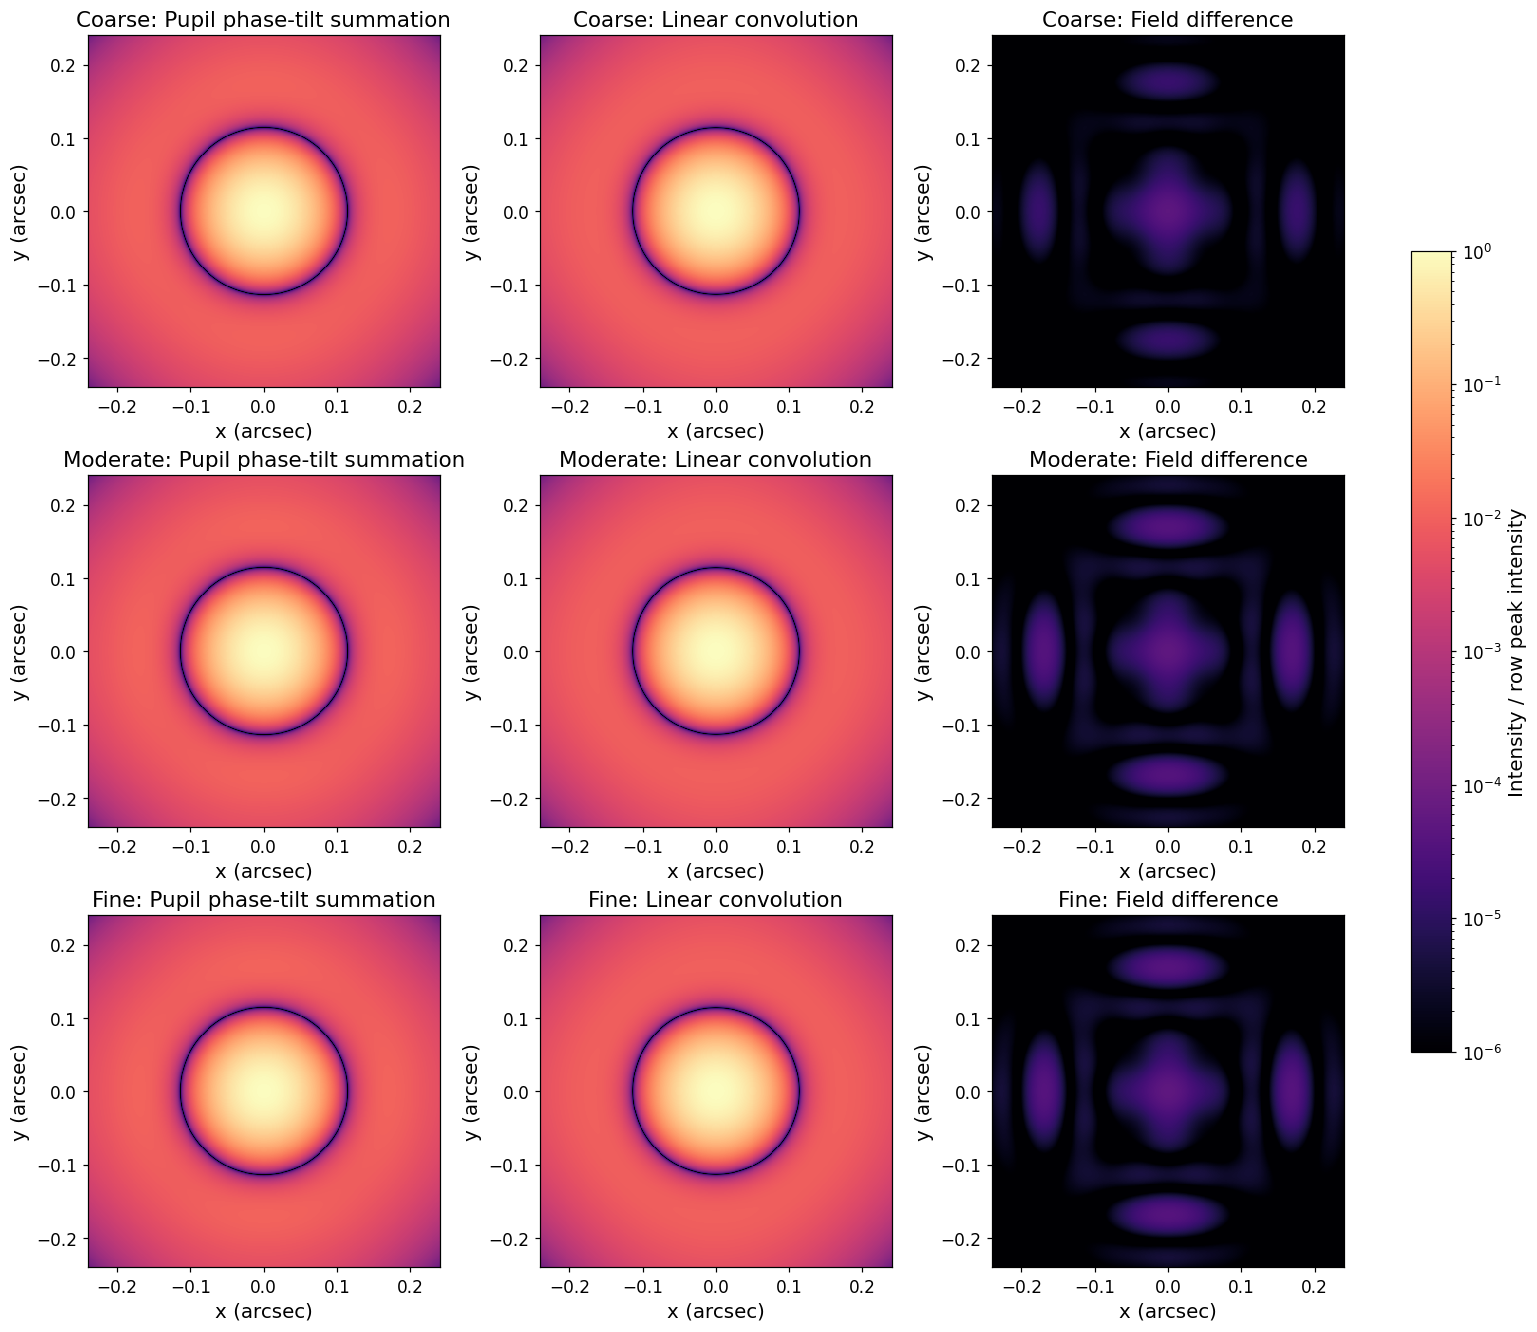

In [41]:
plot_focal_field_resolution_comparison(
    name="Gaussian",
    E_focal_resolution=E_focal_resolution,
    E_focal_convolution=E_focal_convolution,
    x_arcsec=x_arcsec,
    y_arcsec=y_arcsec
)

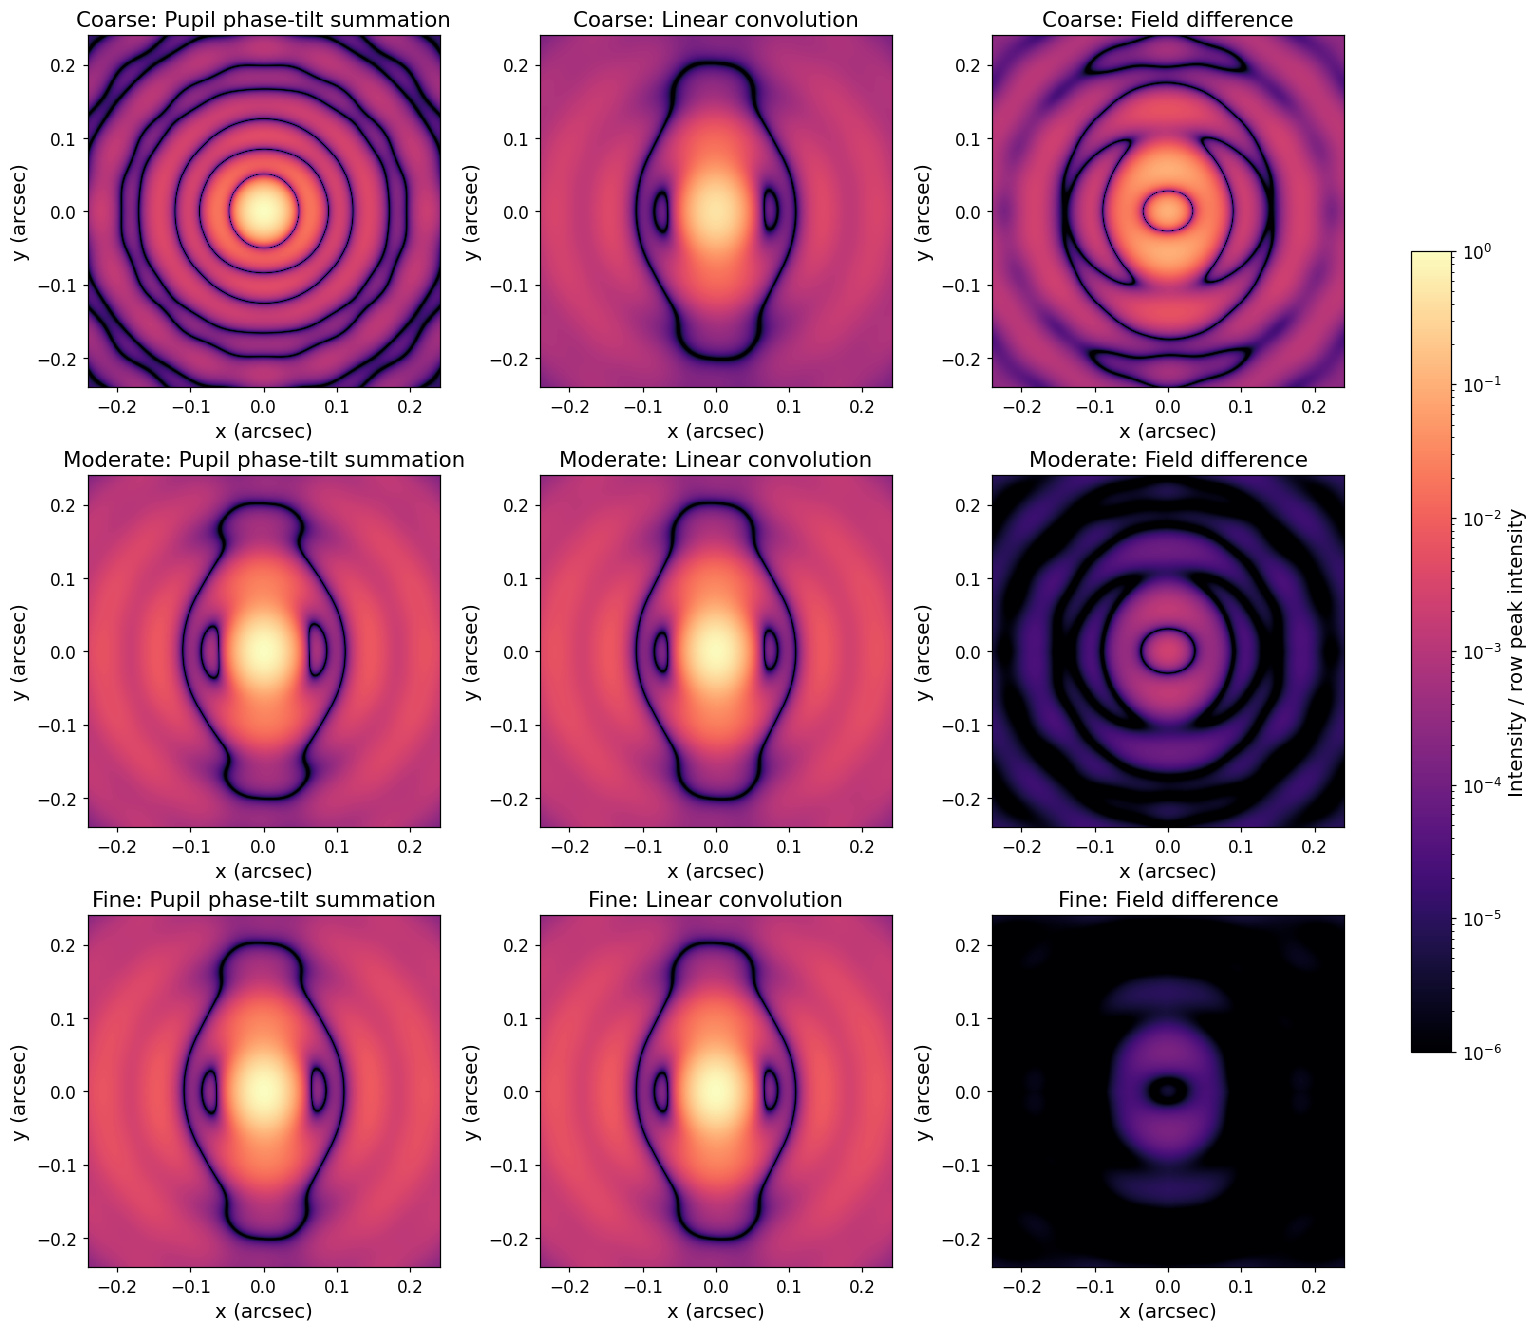

In [42]:
plot_focal_field_resolution_comparison(
    name="Sérsic",
    E_focal_resolution=E_focal_resolution,
    E_focal_convolution=E_focal_convolution,
    x_arcsec=x_arcsec,
    y_arcsec=y_arcsec
)

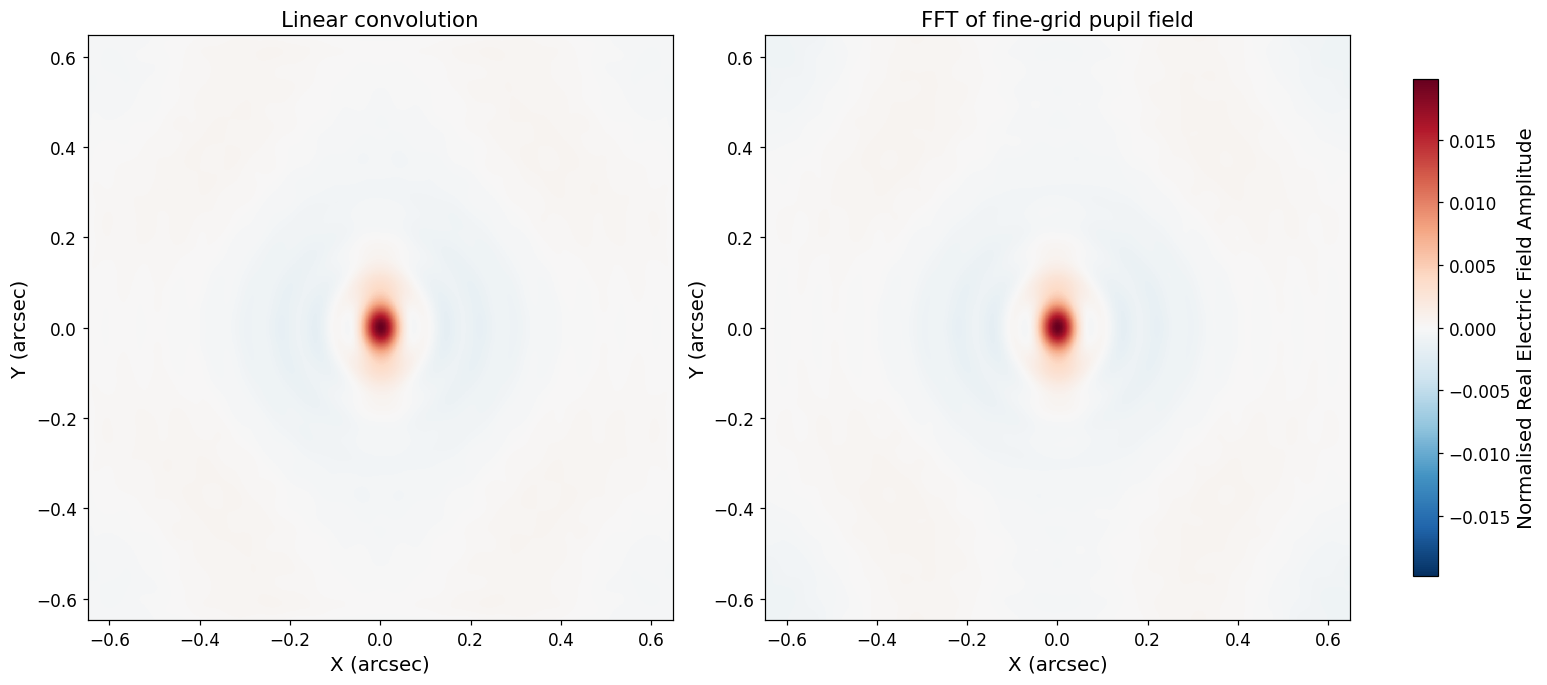

In [43]:
from matplotlib.colors import TwoSlopeNorm

# Focal-plane electric fields.
E_gal_focal = E_focal_convolution["Sérsic"]
E_pupil_fft = E_focal_from_pupil["Sérsic"]

# Normalise both complex fields to unit total power.
E_conv_norm = E_gal_focal / np.linalg.norm(E_gal_focal)
E_pupil_norm = E_pupil_fft / np.linalg.norm(E_pupil_fft)

# Align global phase of convolution with pupil-derived field.
phase = np.angle(np.vdot(E_pupil_norm, E_conv_norm))
E_conv_norm *= np.exp(-1j * phase)

# Compare the real components.
E_real_conv = E_conv_norm.real
E_real_pupil = E_pupil_norm.real

# Shared symmetric colour scale around zero.
vmax = max(
    np.max(np.abs(E_real_conv)),
    np.max(np.abs(E_real_pupil))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, E_real, title in zip(
    axes,
    [E_real_conv, E_real_pupil],
    [
        "Linear convolution",
        "FFT of fine-grid pupil field"
    ]
):
    im = ax.imshow(
        E_real,
        origin="lower",
        interpolation="nearest",
        cmap="RdBu_r",
        norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
        extent=[
            -angular_extent, angular_extent,
            -angular_extent, angular_extent
        ]
    )

    ax.set_title(title)
    ax.set_xlabel("X (arcsec)")
    ax.set_ylabel("Y (arcsec)")
    ax.set_aspect("equal")

fig.colorbar(
    im,
    ax=axes,
    shrink=0.85,
    label="Normalised Real Electric Field Amplitude"
)

plt.show()

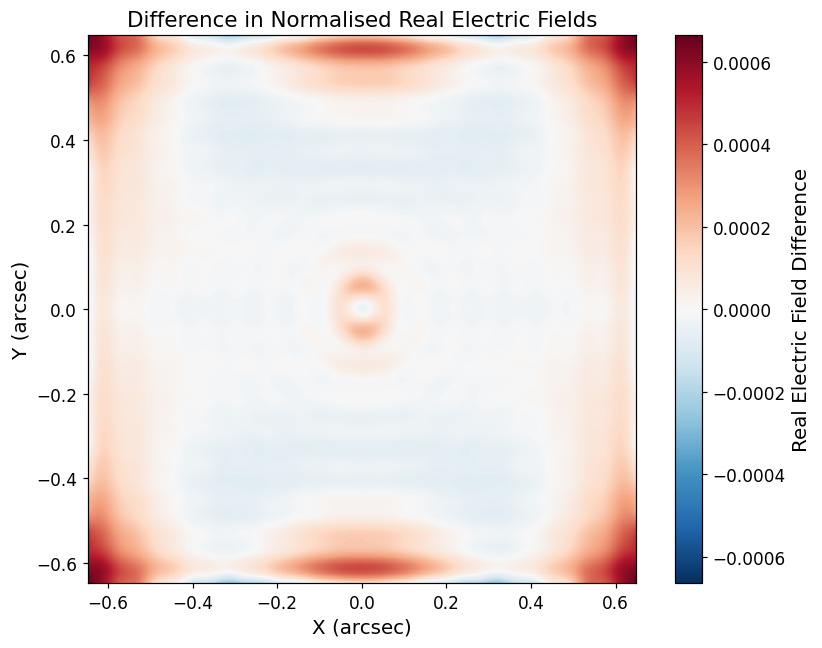

In [44]:
from matplotlib.colors import TwoSlopeNorm

# Difference between normalised real electric fields.
E_real_difference = E_real_conv - E_real_pupil

# Symmetric colour scale centred at zero.
vmax = np.max(np.abs(E_real_difference))

plt.figure(figsize=(8, 6))

im = plt.imshow(
    E_real_difference,
    origin="lower",
    interpolation="nearest",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
    extent=[
        -angular_extent, angular_extent,
        -angular_extent, angular_extent
    ]
)

plt.title("Difference in Normalised Real Electric Fields")
plt.xlabel("X (arcsec)")
plt.ylabel("Y (arcsec)")
plt.colorbar(im, label="Real Electric Field Difference")

plt.tight_layout()
plt.show()

In [45]:
for name in E_source:

    # Method 1: FFT of directly constructed pupil field.
    E_pupil_method = E_focal_from_pupil[name]

    # Method 2: Linear focal-plane convolution.
    E_conv_method = E_focal_convolution[name]

    # Compare total field power.
    P_pupil = np.sum(np.abs(E_pupil_method)**2)
    P_conv = np.sum(np.abs(E_conv_method)**2)

    # Normalise both fields to unit power.
    E_pupil_norm = E_pupil_method / np.sqrt(P_pupil)
    E_conv_norm = E_conv_method / np.sqrt(P_conv)

    # Squared field overlap: 1 means identical spatial fields
    # up to an overall complex scaling factor.
    field_overlap = np.abs(
        np.vdot(E_pupil_norm, E_conv_norm)
    )**2

    print(f"\n{name}")
    print(f"Pupil field power:       {P_pupil:.6e}")
    print(f"Convolution field power: {P_conv:.6e}")
    print(f"Power ratio:             {P_conv/P_pupil:.6f}")
    print(f"Normalised field overlap:{field_overlap:.6f}")


Gaussian
Pupil field power:       2.441666e+03
Convolution field power: 8.572611e+02
Power ratio:             0.351097
Normalised field overlap:0.997207

Sérsic
Pupil field power:       5.565100e+01
Convolution field power: 3.462737e+02
Power ratio:             6.222236
Normalised field overlap:0.985784


In [46]:
phase = np.angle(np.vdot(E_pupil_norm, E_conv_norm))

E_conv_aligned = E_conv_norm * np.exp(-1j * phase)

I_difference = np.abs(
    E_pupil_norm - E_conv_aligned
)**2

In [47]:
I_difference

array([[4.36434868e-07, 4.30602365e-07, 4.25313714e-07, ...,
        4.22594617e-07, 4.27658887e-07, 4.33289135e-07],
       [4.35079270e-07, 4.29029794e-07, 4.23639172e-07, ...,
        4.21109122e-07, 4.26301798e-07, 4.32177002e-07],
       [4.33775374e-07, 4.27564862e-07, 4.22095259e-07, ...,
        4.19763413e-07, 4.25063226e-07, 4.31128306e-07],
       ...,
       [4.32801568e-07, 4.26807637e-07, 4.21559160e-07, ...,
        4.26176591e-07, 4.31650556e-07, 4.37857994e-07],
       [4.33957766e-07, 4.28146073e-07, 4.22997710e-07, ...,
        4.27859096e-07, 4.33265978e-07, 4.39324391e-07],
       [4.35183417e-07, 4.29609150e-07, 4.24582070e-07, ...,
        4.29677154e-07, 4.34992879e-07, 4.40844622e-07]],
      shape=(1000, 1000))

In [48]:
for name, source_data in [
    ("Gaussian", gaussian_fine),
    ("Sérsic", sersic_fine)
]:
    I = source_data["I_source_sky"]

    print(
        f"{name}: "
        f"source_N = {I.shape[0]}, "
        f"peak brightness fraction = {100*I.max():.4f}%"
    )

Gaussian: source_N = 401, peak brightness fraction = 0.0064%
Sérsic: source_N = 401, peak brightness fraction = 5.3917%


## 6. Consistent fibre-mode overlap calculation

Use **the same** `prepare_modes_2d()` output for each method. The pupil overlap denominator uses the **complete** mode norm, not the norm of only the pupil-selected pixels. The focal overlap uses your existing `coupling_efficiency_2d()` function. Any substantial disagreement between `pupil_fine` and `focal_from_pupil` is therefore a propagation, convention, or normalisation bug, not a galaxy sampling issue.

In [49]:
# Reproduce the direct phase-tilt sampling from the uploaded notebook.
# These are intentionally COARSE and serve as a convergence diagnostic only.
gaussian_coarse = prepare_gaussian_source_pupil(
    E_base_pupil, PX, PY, D_M1,
    source_N=21, source_sigma=source_sigma, source_halfwidth=4.0
)

sersic_coarse = prepare_sersic_source_pupil(
    E_base_pupil, PX, PY, D_M1, lam0, model_cent,
    source_N=31, source_halfwidth=source_halfwidth_sersic
)

E_pupil_coarse = {
    'Gaussian': gaussian_coarse['E_source_pupil'],
    'Sérsic': sersic_coarse['E_source_pupil'],
}

print(f"Sérsic 31×31 direct-source peak flux fraction: "
      f"{100*sersic_coarse['I_source_sky'].max():.2f}%")

Sérsic 31×31 direct-source peak flux fraction: 92.83%


In [50]:
source_data_fine = {
    "Gaussian": gaussian_fine,
    "Sérsic": sersic_fine
}

In [55]:
def overlap_at_pupil(E_pupil, E_mode_focal):
    """Coherent modal coupling using a unitary back-propagated mode."""
    E_mode_focal = np.asarray(E_mode_focal, dtype=complex)
    E_mode_focal = E_mode_focal / np.linalg.norm(E_mode_focal)
    E_mode_pupil = ifft2c(E_mode_focal)
    numerator = abs(np.vdot(E_mode_pupil, E_pupil))**2
    denominator = np.vdot(E_pupil, E_pupil).real
    return numerator / denominator


def overlap_at_focal(E_focal, E_mode_focal):
    """Use the fibre overlap integral defined in your package."""
    eta, _, _ = coupling_efficiency_2d(
        E_focal, E_mode_focal, x_1d, y_1d
    )
    return float(np.real(eta))


def compare_methods_at_radius(a, lam0, F_eff, store_modes=False):
    """
    Compute guided modes only ONCE for this radius and use those
    identical modes for both sources and all field-construction methods.
    """
    prepared_modes = prepare_modes_2d(
        x, y, a=a, NA=NA, lam0=lam0,
        az_sym=False, mode_case='few_mode', l_max=10, m_max=5
    )


    data = {}
    per_mode = {}

    for source_name in ["Gaussian", "Sérsic"]:

        eta_incoherent_modes, _ = incoherent_efficiency_pupil_modes(
            source_data=source_data_fine[source_name],
            prepared_modes=prepared_modes,
            E_base_pupil=E_base_pupil,
            PX=PX,
            PY=PY,
            D_M1=D_M1,
            lam0=lam0,
            F_eff=F_eff,
            a=a,
            integration_boundary="core",
            batch_size=16
        )

        totals = {
            "pupil_fine": 0.0,
            "pupil_fine_incoherent": 0.0,
            "focal_from_pupil": 0.0,
            "focal_convolution": 0.0,
            "pupil_coarse": 0.0
        }

        rows = []

        # Your existing mode loop, with enumerate added.
        for i, mode in enumerate(prepared_modes):

            E_m = mode["E_mode"]

            eta_pupil = overlap_at_pupil(
                E_pupil_fine[source_name], E_m
            )
            eta_focal = overlap_at_focal(
                E_focal_from_pupil[source_name], E_m
            )
            eta_linear = overlap_at_focal(
                E_focal_convolution[source_name], E_m
            )
            eta_coarse = overlap_at_pupil(
                E_pupil_coarse[source_name], E_m
            )

            eta_incoherent = eta_incoherent_modes[i]

            totals["pupil_fine"] += eta_pupil
            totals["pupil_fine_incoherent"] += eta_incoherent
            totals["focal_from_pupil"] += eta_focal
            totals["focal_convolution"] += eta_linear
            totals["pupil_coarse"] += eta_coarse

            if store_modes:
                rows.append({
                    "l": mode["l"],
                    "m": mode["m"],
                    "angular": mode["angular"],
                    "cutoff_V": mode.get("cutoff_V", np.nan),

                    "eta_pupil_fine": eta_pupil,
                    "eta_pupil_fine_incoherent": eta_incoherent,
                    "eta_focal_from_pupil": eta_focal,
                    "eta_focal_convolution": eta_linear,
                    "eta_pupil_coarse": eta_coarse,
                })

        data[source_name] = totals
        per_mode[source_name] = rows
    return data, per_mode

In [56]:
compare_methods_at_radius?

Signature: compare_methods_at_radius(a, lam0, F_eff, store_modes=False)
Docstring:
Compute guided modes only ONCE for this radius and use those
identical modes for both sources and all field-construction methods.
File:      /var/folders/pk/ftg5vwzs3r1dhbzyhbqk09580000gp/T/ipykernel_83606/2266681475.py
Type:      function

In [58]:
# First: one core radius, before running the potentially expensive sweep.
a_test = 5.7e-6
single_radius_results, single_radius_modes = compare_methods_at_radius(
    a=a_test, lam0=lam0, F_eff=F_fibre, store_modes=True, 
)

print(f'Core radius: {a_test*1e6:.2f} µm; V={2*np.pi*a_test*NA/lam0:.3f}')
for source_name, vals in single_radius_results.items():
    print(f'\n{source_name}')
    for method, eta in vals.items():
        print(f'  {method:<20}: {eta:.8f}')
    print('  Pupil vs focal FFT difference:',
          abs(vals['pupil_fine'] - vals['focal_from_pupil']))

Core radius: 5.70 µm; V=2.388

Gaussian
  pupil_fine          : 0.50272444
  pupil_fine_incoherent: 0.44760644
  focal_from_pupil    : 0.50283621
  focal_convolution   : 0.50913003
  pupil_coarse        : 0.50293637
  Pupil vs focal FFT difference: 0.00011176917952693266

Sérsic
  pupil_fine          : 0.66105225
  pupil_fine_incoherent: 0.55821641
  focal_from_pupil    : 0.66128199
  focal_convolution   : 0.66808971
  pupil_coarse        : 0.77997455
  Pupil vs focal FFT difference: 0.00022974376983264655


## 7. Core-radius sweep — preview first, full thesis-resolution sweep on demand

`RUN_FULL_SWEEP=False` runs a smaller diagnostic sweep without changing the physics. Set it to `True` to reproduce the original 276-point radius grid on your Mac. No numerical results have been invented for this notebook.

In [ ]:
# RUN_FULL_SWEEP = False
# core_radius_range = (
#     np.linspace(2.5e-6, 30e-6, 276)
#     if RUN_FULL_SWEEP else
#     np.linspace(2.5e-6, 30e-6, 18)
# )

# methods = (
#     "pupil_fine",
#     "pupil_fine_incoherent",
#     "focal_from_pupil",
#     "focal_convolution",
#     "pupil_coarse"
# )

# sweep = {
#     source: {method: [] for method in methods}
#     for source in ("Gaussian", "Sérsic")
# }

# mode_results_by_radius = {'Gaussian': [], 'Sérsic': []}

# for a in tqdm(core_radius_range, desc='Coherent coupling: core radius'):
#     by_source, by_mode = compare_methods_at_radius(a, store_modes=True)
#     for source in sweep:
#         for method in sweep[source]:
#             sweep[source][method].append(by_source[source][method])
#         mode_results_by_radius[source].append(by_mode[source])

# for source in sweep:
#     for method in sweep[source]:
#         sweep[source][method] = np.asarray(sweep[source][method])

# V_array = 2 * np.pi * core_radius_range * NA / lam0

Coherent coupling: core radius:   0%|          | 0/18 [00:00<?, ?it/s]

TypeError: compare_methods_at_radius() missing 2 required positional arguments: 'lam0' and 'F_eff'

In [61]:
from joblib import Parallel, delayed
import numpy as np

# ============================================================
# 1. Set up core-radius sweep
# ============================================================

RUN_FULL_SWEEP = True

core_radius_range = (
    np.linspace(2.5e-6, 30e-6, 276)
    if RUN_FULL_SWEEP else
    np.linspace(2.5e-6, 30e-6, 18)
)

# Parallel processing settings.
n_jobs = 4

methods = (
    "pupil_fine",
    "pupil_fine_incoherent",
    "focal_from_pupil",
    "focal_convolution",
    "pupil_coarse"
)

# ============================================================
# 2. Define calculation for one core radius
# ============================================================

def run_one_radius(a):
    """
    Calculate coupling efficiencies for all methods and
    individual LP modes at one fibre core radius.
    """

    by_source, by_mode = compare_methods_at_radius(
        a, lam0=lam0, F_eff=F_fibre,
        store_modes=True
    )

    return by_source, by_mode


# ============================================================
# 3. Run the radius sweep in parallel
# ============================================================

results = Parallel(
    n_jobs=n_jobs,
    backend="threading",
    verbose=10
)(
    delayed(run_one_radius)(a)
    for a in core_radius_range
)


# ============================================================
# 4. Organise total and individual mode results
# ============================================================

sweep = {
    source: {method: [] for method in methods}
    for source in ("Gaussian", "Sérsic")
}

mode_results_by_radius = {
    "Gaussian": [],
    "Sérsic": []
}

for by_source, by_mode in results:

    for source in sweep:

        # Store total coupling efficiencies.
        for method in methods:
            sweep[source][method].append(
                by_source[source][method]
            )

        # Store individual LP-mode efficiencies.
        mode_results_by_radius[source].append(
            by_mode[source]
        )


# ============================================================
# 5. Convert results to NumPy arrays
# ============================================================

for source in sweep:
    for method in methods:
        sweep[source][method] = np.asarray(
            sweep[source][method]
        )

V_array = (
    2 * np.pi * core_radius_range * NA / lam0
)

print("Full coupling sweep complete.")

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    3.4s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    8.4s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   10.3s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:   15.1s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   27.5s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   36.1s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   48.2s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:  1.6min
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:  2.1min
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  2.8min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  3.7min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  4.9min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:  6.3min
[Para

Full coupling sweep complete.


[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed: 22.4min finished


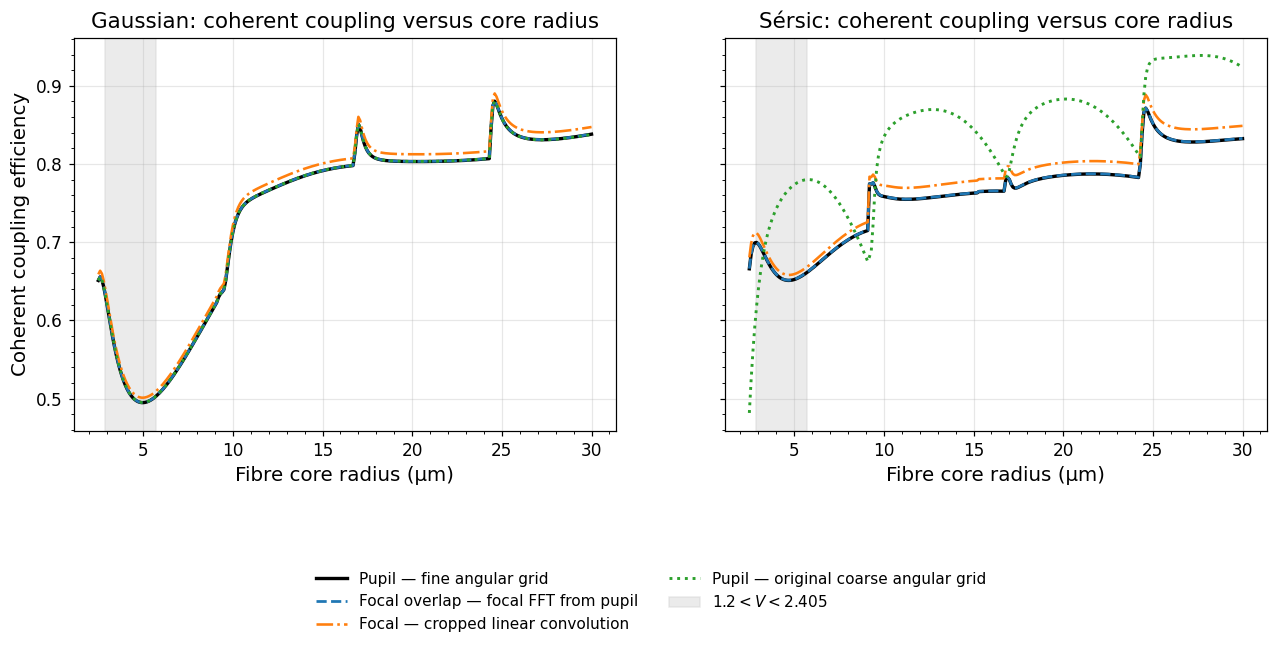

In [62]:
# Figure 4 — clearly distinguish numerically equivalent vs different-approximation curves.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, source in zip(axes, ('Gaussian', 'Sérsic')):
    d = sweep[source]
    ax.plot(core_radius_range*1e6, d['pupil_fine'], 'k-', lw=2.2,
            label='Pupil — fine angular grid')
    ax.plot(core_radius_range*1e6, d['focal_from_pupil'], '--', lw=1.8,
            label='Focal overlap — focal FFT from pupil') # same thing as pupil_fine but transformed to focal plane
    ax.plot(core_radius_range*1e6, d['focal_convolution'], '-.', lw=1.7,
            label='Focal — cropped linear convolution')
    ax.plot(core_radius_range*1e6, d['pupil_coarse'], ':', lw=1.9,
            label='Pupil — original coarse angular grid')
    ax.axvspan(1.2*lam0/(2*np.pi*NA)*1e6,
               2.405*lam0/(2*np.pi*NA)*1e6,
               color='lightgrey', alpha=0.45, label=r'$1.2<V<2.405$')
    ax.set(xlabel='Fibre core radius (µm)',
           title=f'{source}: coherent coupling versus core radius')
    ax.grid(alpha=0.3)
    ax.minorticks_on()
axes[0].set_ylabel('Coherent coupling efficiency')
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02),
           ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.23)
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(exist_ok=True)
    fig.savefig(FIGURE_DIR/'04_coherent_coupling_comparison.png', dpi=220, bbox_inches='tight')
plt.show()

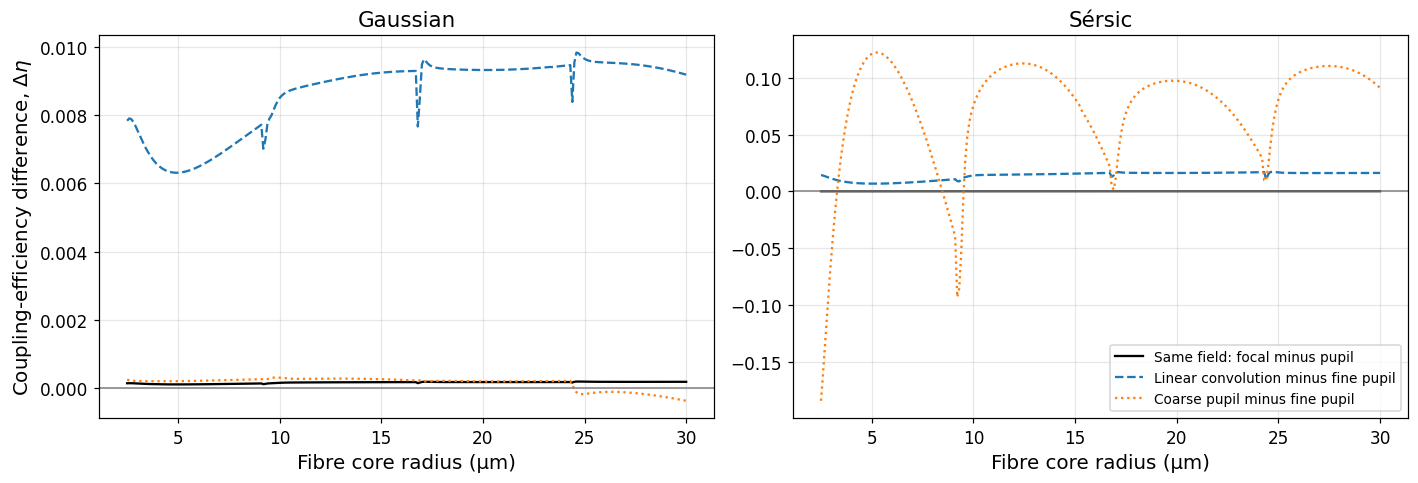

In [63]:
# Figure 5 — quantify discrepancies in absolute coupling efficiency.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, source in zip(axes, ('Gaussian', 'Sérsic')):
    d = sweep[source]
    ax.plot(core_radius_range*1e6,
            d['focal_from_pupil'] - d['pupil_fine'],
            'k-', label='Same field: focal minus pupil')
    ax.plot(core_radius_range*1e6,
            d['focal_convolution'] - d['pupil_fine'],
            '--', label='Linear convolution minus fine pupil')
    ax.plot(core_radius_range*1e6,
            d['pupil_coarse'] - d['pupil_fine'],
            ':', label='Coarse pupil minus fine pupil')
    ax.axhline(0, color='gray', lw=1)
    ax.set(xlabel='Fibre core radius (µm)', title=source)
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r'Coupling-efficiency difference, $\Delta\eta$')
axes[1].legend(loc='best', fontsize=9)
finish_figure(fig, '05_coupling_differences.png')

In [64]:
def select_mode_results_by_method(
    mode_results_by_radius,
    source,
    method
):
    """
    Extract individual LP mode efficiencies for one source
    and one coupling calculation method.

    Returns the same data structure expected by the
    existing LP-mode plotting functions.
    """

    eta_key = f"eta_{method}"

    selected_results = []

    for modes_at_radius in mode_results_by_radius[source]:

        modes_selected = []

        for mode in modes_at_radius:

            modes_selected.append({
                "l": mode["l"],
                "m": mode["m"],
                "angular": mode["angular"],
                "cutoff_V": mode["cutoff_V"],
                "eta": mode[eta_key]
            })

        selected_results.append(modes_selected)

    return selected_results

In [65]:
def extract_coherent_lp_families(
    results_by_radius,
    core_radius_array,
    method="pupil_fine"
):
    """
    Extract coherent coupling efficiencies for each LP mode family.

    For asymmetric modes (l > 0), sum the cosine and sine
    contributions belonging to the same LP family.

    Symmetric modes (l = 0) are kept individually.

    Parameters
    ----------
    results_by_radius : list
        Per-mode results for each core radius, containing
        the coupling efficiency from each calculation method.

    core_radius_array : array
        Fibre core radii [m].

    method : str
        Coupling calculation method:
            "pupil_fine"
            "focal_from_pupil"
            "focal_convolution"
            "pupil_coarse"

    Returns
    -------
    families : dict
        Coupling efficiency arrays for each LP mode family.

        NaN indicates that the mode is unsupported.
        A genuine zero coupling efficiency remains zero.
    """

    eta_key = f"eta_{method}"

    n_r = len(core_radius_array)

    families = {}

    # Loop through each fibre core radius.
    for idx, rows in enumerate(results_by_radius):

        # Loop through the LP modes supported at this radius.
        for mode in rows:

            l = int(mode["l"])
            m = int(mode["m"])

            # Combine cos and sin components under the same label.
            label = f"LP{l}{m}"

            if label not in families:
                families[label] = np.full(n_r, np.nan)

            # Initialise the efficiency to zero only where
            # the mode is supported.
            if not np.isfinite(families[label][idx]):
                families[label][idx] = 0.0

            # Add the efficiency of the selected method.
            families[label][idx] += mode[eta_key]

    return families

def plot_coherent_lp_mode_families(
    core_radius_array,
    total_eta,
    results_by_radius,
    lam0,
    NA,
    method="pupil_fine",
    source_name="Sérsic"
):
    """
    Plot total coherent coupling efficiency and individual
    LP mode-family contributions for a selected method.

    Cosine and sine components of asymmetric LP modes
    are combined into the same mode family.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii [m].

    total_eta : array
        Total coherent coupling efficiency for the selected method.

    results_by_radius : list
        Per-mode coupling results at each core radius.

    lam0 : float
        Wavelength [m].

    NA : float
        Fibre numerical aperture.

    method : str
        "pupil_fine", "focal_from_pupil",
        "focal_convolution", or "pupil_coarse".

    source_name : str
        Name of the source, e.g. "Sérsic" or "Gaussian".

    Returns
    -------
    families : dict
        Extracted LP mode-family coupling efficiency arrays.
    """

    # ========================================================
    # 1. Extract LP mode-family efficiencies
    # ========================================================

    families = extract_coherent_lp_families(
        results_by_radius=results_by_radius,
        core_radius_array=core_radius_array,
        method=method
    )

    # Sort mode families by their first supported core radius.
    names = sorted(
        families,
        key=lambda name: np.where(
            np.isfinite(families[name])
        )[0][0]
    )

    # ========================================================
    # 2. Assign colours and line styles
    # ========================================================

    colours = plt.cm.turbo(
        np.linspace(0, 1, max(len(names), 1))
    )

    styles = [
        "--",
        ":",
        "-.",
        (0, (5, 2)),
        (0, (3, 1, 1, 1)),
        (0, (1, 1))
    ]

    # ========================================================
    # 3. Plot total and individual LP efficiencies
    # ========================================================

    fig, ax = plt.subplots(figsize=(11, 6))

    # Total coherent coupling efficiency.
    ax.plot(
        core_radius_array * 1e6,
        total_eta,
        color="black",
        lw=2.4,
        label=f"Total coherent {source_name} coupling"
    )

    # Individual LP mode families.
    for i, name in enumerate(names):

        ax.plot(
            core_radius_array * 1e6,
            families[name],
            color=colours[i],
            lw=1.8,
            ls=styles[i % len(styles)],
            label=name
        )

    # ========================================================
    # 4. Shade the single-mode region
    # ========================================================

    ax.axvspan(
        1.2 * lam0 / (2 * np.pi * NA) * 1e6,
        2.405 * lam0 / (2 * np.pi * NA) * 1e6,
        color="lightgrey",
        alpha=0.4
    )

    # ========================================================
    # 5. Axis formatting
    # ========================================================

    ax.set(
        xlabel="Fibre core radius (µm)",
        ylabel=f"Coherent {source_name} coupling efficiency",
        title=f"{source_name}: LP mode families ({method})"
    )

    ax.grid(alpha=0.3)
    ax.minorticks_on()

    ax.legend(
        ncol=3,
        fontsize=9,
        loc="best"
    )

    # ========================================================
    # 6. Secondary x-axis: V-number
    # ========================================================

    ax_top = ax.secondary_xaxis(
        "top",
        functions=(
            lambda radius_um:
                2 * np.pi * radius_um * 1e-6 * NA / lam0,

            lambda V:
                V * lam0 / (2 * np.pi * NA) * 1e6
        )
    )

    ax_top.set_xlabel("Normalised frequency, V")

    # ========================================================
    # 7. Save and display
    # ========================================================

    filename = (
        f"{source_name.lower()}_{method}_mode_families.png"
    )

    finish_figure(fig, filename)

    return families

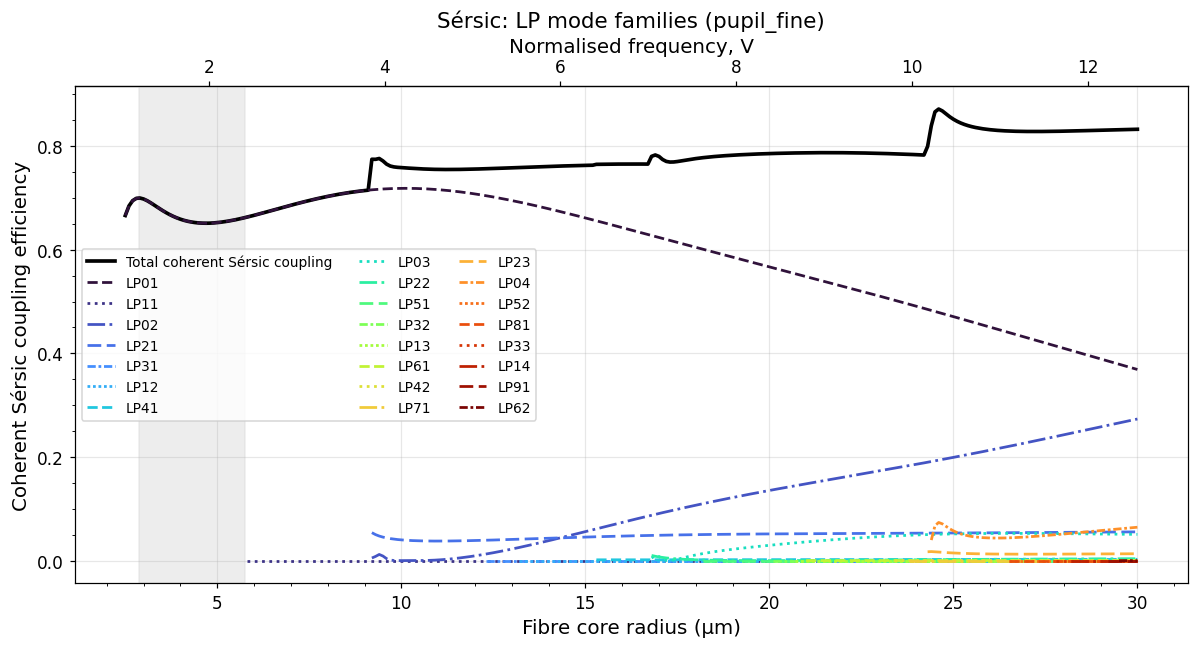

In [66]:
sersic_pupil_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=sweep["Sérsic"]["pupil_fine"],
    results_by_radius=mode_results_by_radius["Sérsic"],
    lam0=lam0,
    NA=NA,
    method="pupil_fine",
    source_name="Sérsic"
)

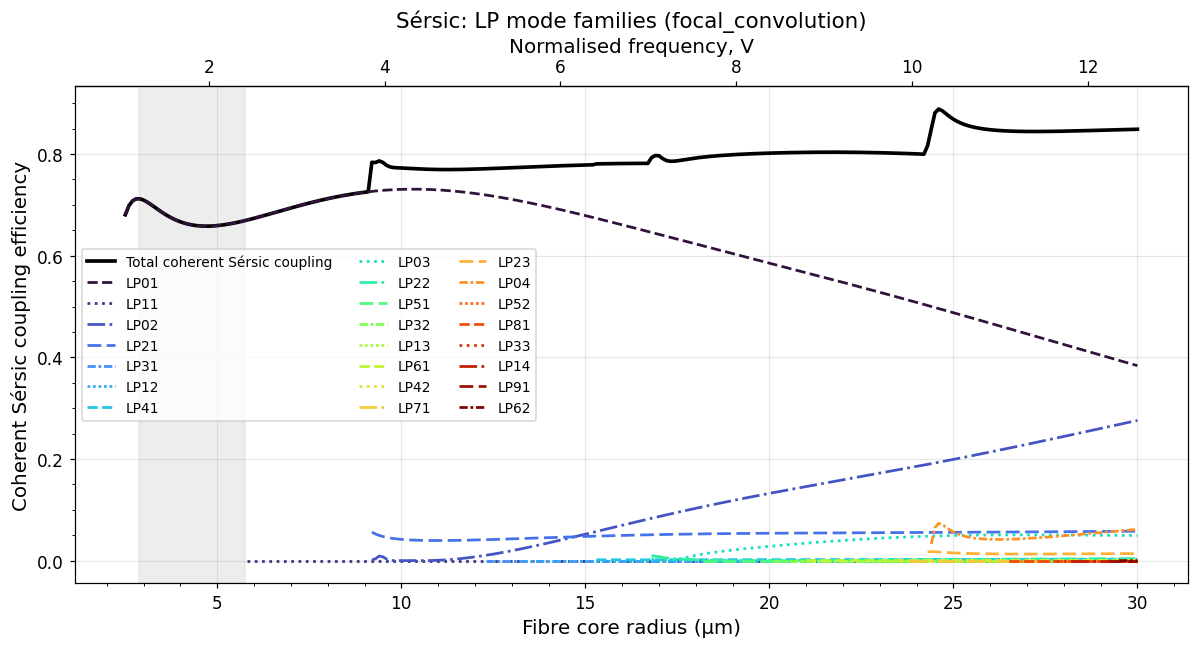

In [67]:
sersic_focal_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=sweep["Sérsic"]["focal_convolution"],
    results_by_radius=mode_results_by_radius["Sérsic"],
    lam0=lam0,
    NA=NA,
    method="focal_convolution",
    source_name="Sérsic"
)

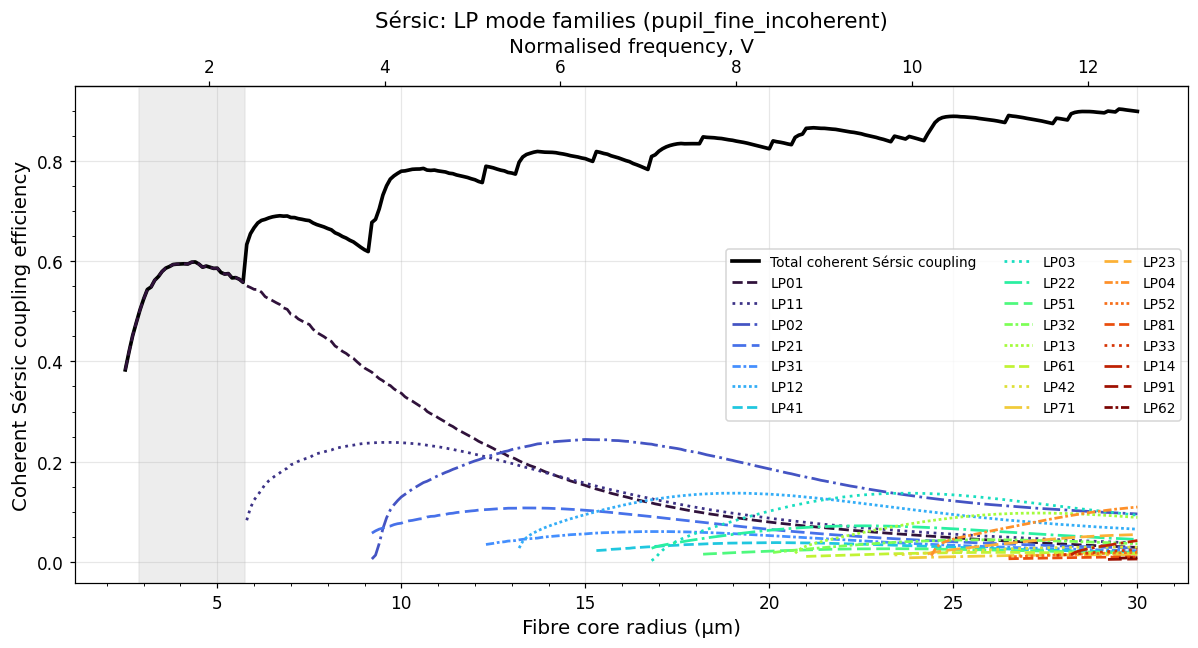

In [68]:
sersic_incoherent_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=sweep["Sérsic"]["pupil_fine_incoherent"],
    results_by_radius=mode_results_by_radius["Sérsic"],
    lam0=lam0,
    NA=NA,
    method="pupil_fine_incoherent",
    source_name="Sérsic"
)

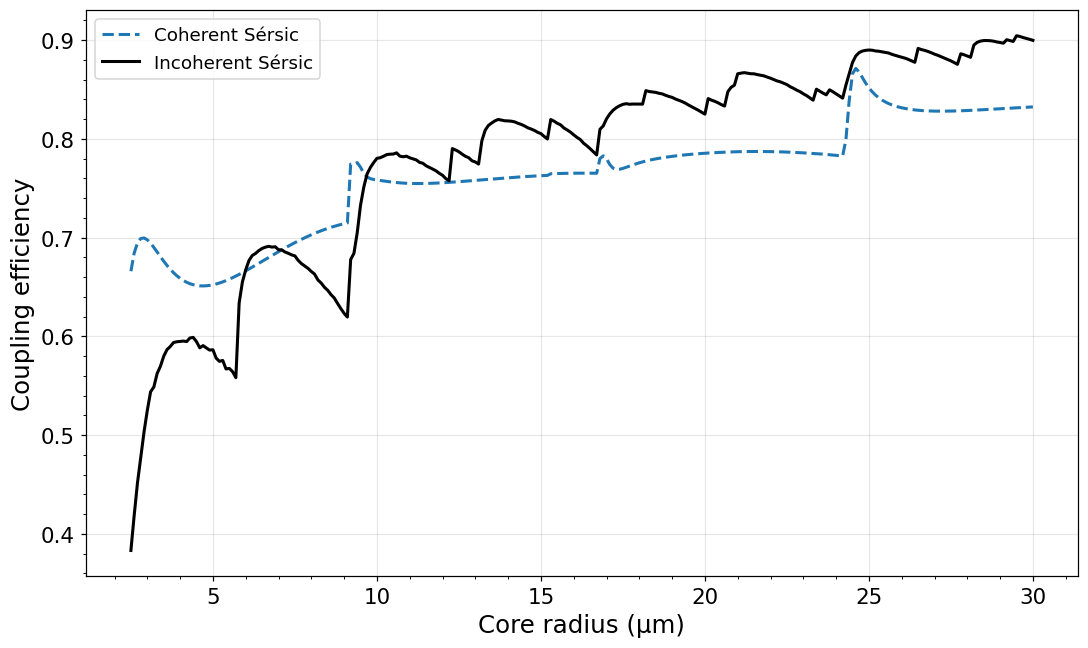

In [69]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    core_radius_range * 1e6,
    sweep["Sérsic"]["pupil_fine"],
    color="tab:blue",
    linestyle="--",
    linewidth=2,
    label="Coherent Sérsic"
)

ax.plot(
    core_radius_range * 1e6,
    sweep["Sérsic"]["pupil_fine_incoherent"],
    color="k",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Sérsic"
)

ax.set_xlabel("Core radius (µm)", fontsize=16)
ax.set_ylabel("Coupling efficiency", fontsize=16)

ax.tick_params(axis="both", labelsize=14)
ax.minorticks_on()
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

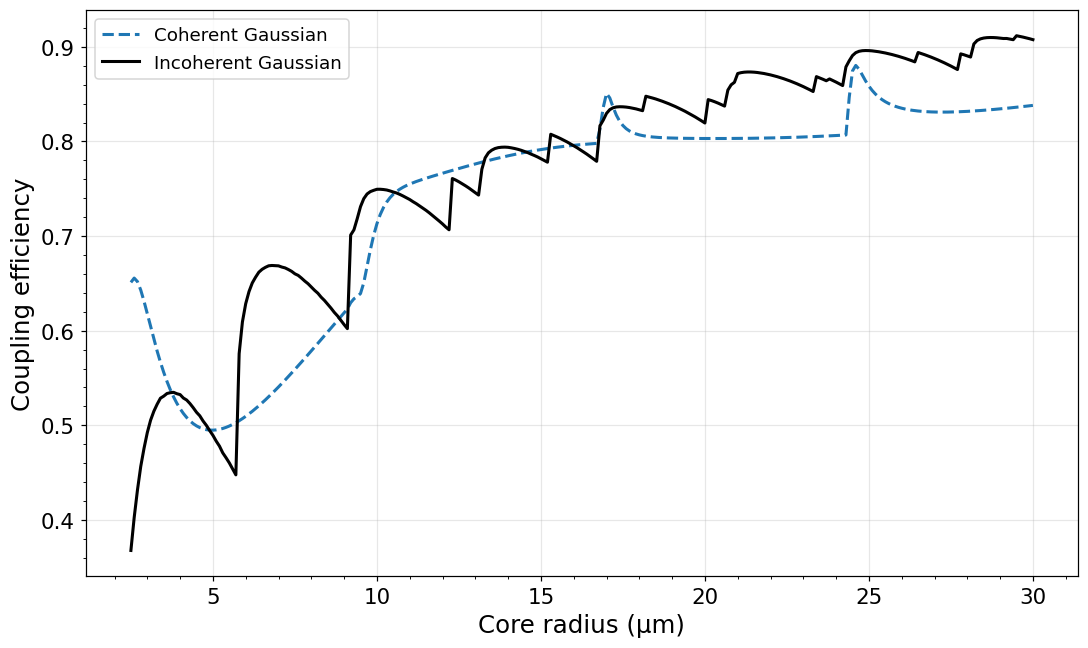

In [70]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    core_radius_range * 1e6,
    sweep["Gaussian"]["pupil_fine"],
    color="tab:blue",
    linestyle="--",
    linewidth=2,
    label="Coherent Gaussian"
)

ax.plot(
    core_radius_range * 1e6,
    sweep["Gaussian"]["pupil_fine_incoherent"],
    color="black",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Gaussian"
)

ax.set_xlabel("Core radius (µm)", fontsize=16)
ax.set_ylabel("Coupling efficiency", fontsize=16)

ax.tick_params(axis="both", labelsize=14)
ax.minorticks_on()
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [71]:
# Geometrical image-plane position of each sky source element [m].
r_source = (
    F_fibre * lam0
    * np.hypot(
        source_data["QX"],
        source_data["QY"]
    )
)

# Include only source positions projected inside the fibre core.
core_mask = r_source <= a

In [72]:
def incoherent_efficiency_pupil_modes(
    source_data,
    prepared_modes,
    E_base_pupil,
    PX, PY,
    D_M1,
    lam0,
    F_eff,
    a,
    integration_boundary="full",
    batch_size=16
):
    """
    Calculate incoherent extended-source coupling efficiency
    into every prepared fibre mode.

    Parameters
    ----------
    integration_boundary : str
        "full" : Include all sampled source positions.

        "core" : Include only source positions whose
                 geometrical image-plane radius is <= a.

    a : float
        Fibre core radius [m].

    F_eff : float
        Effective focal ratio at the fibre input.

    Returns
    -------
    eta_modes : 1D array
        Incoherent efficiency of each fibre mode.

    source_flux_fraction : float
        Fraction of the sampled source brightness within
        the selected integration boundary.
    """

    # ========================================================
    # 1. Extract active telescope pupil coordinates
    # ========================================================

    pupil_indices = source_data["pupil_indices"]

    PX_active = PX.ravel()[pupil_indices]
    PY_active = PY.ravel()[pupil_indices]

    E_base_active = (
        E_base_pupil.ravel()[pupil_indices].copy()
    )

    E_base_active /= np.linalg.norm(E_base_active)

    # ========================================================
    # 2. Source angular coordinates and brightness
    # ========================================================

    QX_flat = source_data["QX"].ravel()
    QY_flat = source_data["QY"].ravel()

    I_source_flat = source_data["I_source_sky"].ravel().copy()

    # ========================================================
    # 3. Apply the integration boundary
    # ========================================================

    if integration_boundary == "core":

        # Convert angular positions into geometrical
        # image-plane distances from the fibre centre [m].
        r_source = (
            F_eff * lam0
            * np.hypot(QX_flat, QY_flat)
        )

        core_mask = r_source <= a

        # Exclude source elements outside the fibre core.
        I_source_flat[~core_mask] = 0.0

    elif integration_boundary != "full":

        raise ValueError(
            "integration_boundary must be 'full' or 'core'."
        )

    # Fraction of the original sampled source brightness
    # retained within the integration boundary.
    source_flux_fraction = np.sum(I_source_flat)

    if source_flux_fraction <= 0:
        raise ValueError(
            "No source brightness falls within the boundary."
        )

    # Normalise to the brightness within the selected region.
    # This reproduces a weighted-average efficiency
    # whose denominator is the selected source flux.
    I_source_flat /= source_flux_fraction

    # ========================================================
    # 4. Prepare fibre modes in the pupil plane
    # ========================================================

    mode_fields = []
    mode_powers = []

    for mode in prepared_modes:

        E_mode_pupil = ifft2c(
            mode["E_mode"]
        )

        # Full mode power before restricting to pupil pixels.
        P_mode = np.vdot(
            E_mode_pupil,
            E_mode_pupil
        ).real

        mode_powers.append(P_mode)

        mode_fields.append(
            E_mode_pupil.ravel()[pupil_indices]
        )

    mode_fields = np.column_stack(mode_fields)
    mode_powers = np.asarray(mode_powers)

    eta_modes = np.zeros(len(prepared_modes))

    # ========================================================
    # 5. Calculate incoherent modal powers in batches
    # ========================================================

    for first in range(0, QX_flat.size, batch_size):

        last = min(
            first + batch_size,
            QX_flat.size
        )

        # Skip batches containing no selected source brightness.
        weights = I_source_flat[first:last]

        if not np.any(weights > 0):
            continue

        # Geometrical phase tilts of individual source elements.
        tilt = np.exp(
            2j * np.pi / D_M1 * (
                QX_flat[first:last, None] * PX_active[None, :]
                +
                QY_flat[first:last, None] * PY_active[None, :]
            )
        )

        E_point_pupil = (
            tilt * E_base_active[None, :]
        )

        # Point-source overlap with every fibre mode.
        amplitudes = (
            E_point_pupil @ np.conj(mode_fields)
        )

        # Incoherent intensity-weighted modal powers.
        eta_modes += np.sum(
            weights[:, None] * np.abs(amplitudes)**2,
            axis=0
        )

    # Each point-source pupil field has unit power.
    eta_modes /= mode_powers

    return eta_modes, source_flux_fraction

In [73]:
from joblib import Parallel, delayed

def run_one_radius_incoherent_core(a):

    # Prepare fibre modes for the current core radius.
    prepared_modes = prepare_modes_2d(
        x, y,
        a=a,
        NA=NA,
        lam0=lam0,
        az_sym=False,
        mode_case="few_mode",
        l_max=10,
        m_max=5
    )

    results = {}

    # Calculate Gaussian and Sérsic separately.
    for source_name in ("Gaussian", "Sérsic"):

        eta_modes, flux_fraction = incoherent_efficiency_pupil_modes(
            source_data=source_data_fine[source_name],
            prepared_modes=prepared_modes,
            E_base_pupil=E_base_pupil,
            PX=PX,
            PY=PY,
            D_M1=D_M1,
            lam0=lam0,
            F_eff=F_fibre,
            a=a,
            integration_boundary="core",
            batch_size=16
        )

        results[source_name] = {
            "eta_modes": eta_modes,
            "eta_total": np.sum(eta_modes),
            "flux_fraction": flux_fraction,
        }

    return results


# Run calculations in parallel with joblib progress messages.
results_incoherent_core = Parallel(
    n_jobs=4,
    backend="threading",
    verbose=10
)(
    delayed(run_one_radius_incoherent_core)(a)
    for a in core_radius_range
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    2.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    5.1s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    7.3s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:   10.1s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   16.1s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   21.9s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   28.4s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   42.6s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   55.9s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  2.3min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  3.0min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:  3.9min
[Para

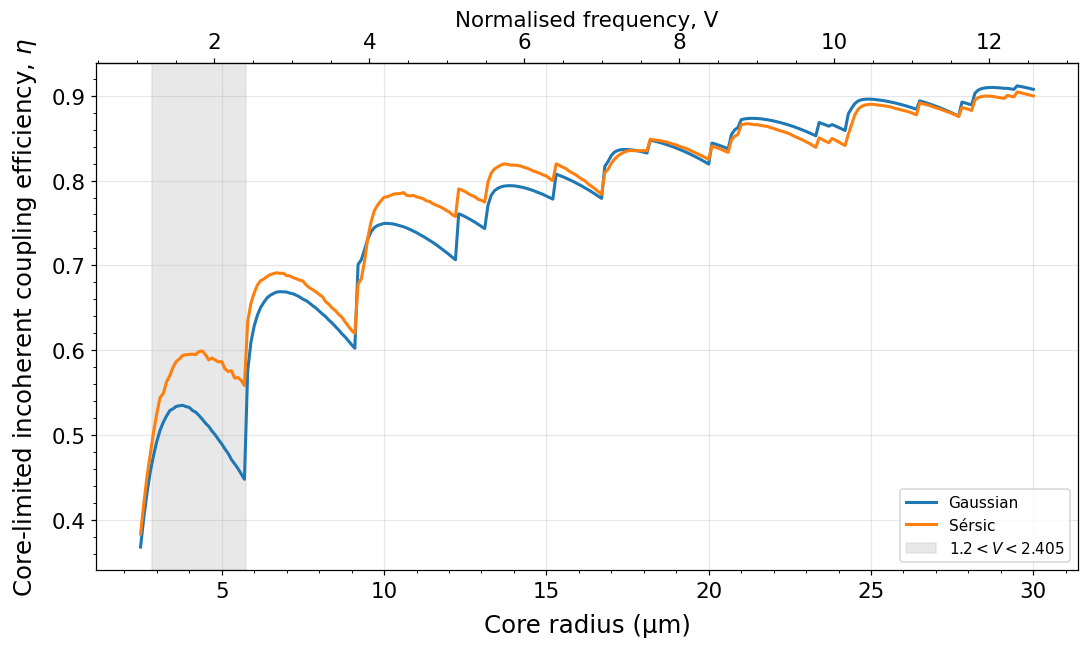

In [74]:
# Extract total core-limited incoherent coupling efficiencies.
eta_gaussian_core = np.array([
    result["Gaussian"]["eta_total"]
    for result in results_incoherent_core
])

eta_sersic_core = np.array([
    result["Sérsic"]["eta_total"]
    for result in results_incoherent_core
])

# ============================================================
# Plot core-limited incoherent coupling vs fibre core radius
# ============================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    core_radius_range * 1e6,
    eta_gaussian_core,
    color="tab:blue",
    linewidth=2,
    label="Gaussian"
)

ax1.plot(
    core_radius_range * 1e6,
    eta_sersic_core,
    color="tab:orange",
    linewidth=2,
    label="Sérsic"
)

# Shade single-mode region.
ax1.axvspan(
    1.2 * lam0 / (2 * np.pi * NA) * 1e6,
    2.405 * lam0 / (2 * np.pi * NA) * 1e6,
    color="lightgrey",
    alpha=0.5,
    label=r"$1.2 < V < 2.405$"
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(
    r"Core-limited incoherent coupling efficiency, $\eta$",
    fontsize=16,
    labelpad=8
)

ax1.tick_params(axis="both", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Top x-axis: V-number.
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(
        lambda radius_um: 2 * np.pi * radius_um * 1e-6 * NA / lam0,
        lambda V: V * lam0 / (2 * np.pi * NA) * 1e6
    )
)

ax_top.set_xlabel("Normalised frequency, V", fontsize=14)
ax_top.tick_params(axis="x", labelsize=14)
ax_top.minorticks_on()

ax1.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [75]:
# ============================================================
# 1. Extract total core-limited incoherent efficiencies
# ============================================================

eta_sersic_incoherent_core = np.array([
    result["Sérsic"]["eta_total"]
    for result in results_incoherent_core
])

eta_gaussian_incoherent_core = np.array([
    result["Gaussian"]["eta_total"]
    for result in results_incoherent_core
])


# ============================================================
# 2. Extract individual LP-mode coupling efficiencies
# ============================================================

sersic_incoherent_core_modes = []
gaussian_incoherent_core_modes = []

for i, result in enumerate(results_incoherent_core):

    # Individual LP-mode efficiencies at the current radius.
    eta_sersic_modes = result["Sérsic"]["eta_modes"]
    eta_gaussian_modes = result["Gaussian"]["eta_modes"]

    # Reuse the LP-mode information from the original sweep.
    original_sersic_modes = mode_results_by_radius["Sérsic"][i]
    original_gaussian_modes = mode_results_by_radius["Gaussian"][i]

    # Check that the number of modes matches.
    assert len(eta_sersic_modes) == len(original_sersic_modes)
    assert len(eta_gaussian_modes) == len(original_gaussian_modes)

    modes_at_radius_sersic = []
    modes_at_radius_gaussian = []

    # Store Sérsic LP-mode efficiencies.
    for j, mode in enumerate(original_sersic_modes):

        modes_at_radius_sersic.append({
            "l": mode["l"],
            "m": mode["m"],
            "angular": mode["angular"],
            "cutoff_V": mode["cutoff_V"],
            "eta_pupil_fine_incoherent_core": eta_sersic_modes[j]
        })

    # Store Gaussian LP-mode efficiencies.
    for j, mode in enumerate(original_gaussian_modes):

        modes_at_radius_gaussian.append({
            "l": mode["l"],
            "m": mode["m"],
            "angular": mode["angular"],
            "cutoff_V": mode["cutoff_V"],
            "eta_pupil_fine_incoherent_core": eta_gaussian_modes[j]
        })

    # Append results to the appropriate source.
    sersic_incoherent_core_modes.append(modes_at_radius_sersic)
    gaussian_incoherent_core_modes.append(modes_at_radius_gaussian)

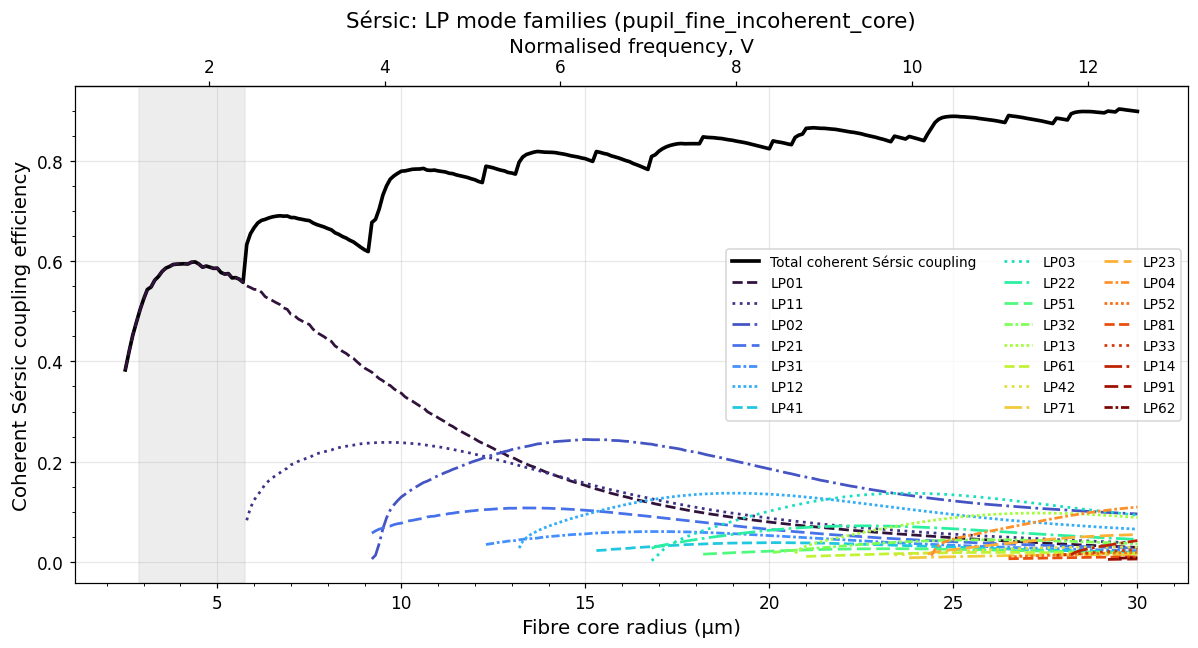

In [76]:
sersic_incoherent_core_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=eta_sersic_incoherent_core,
    results_by_radius=sersic_incoherent_core_modes,
    lam0=lam0,
    NA=NA,
    method="pupil_fine_incoherent_core",
    source_name="Sérsic"
)

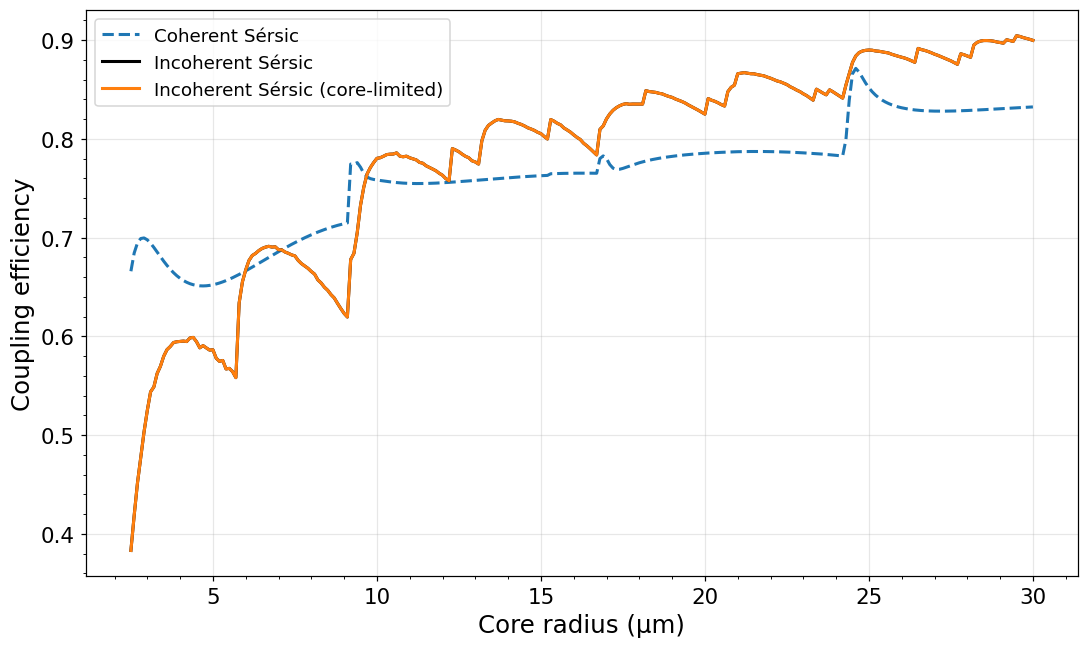

In [77]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    core_radius_range * 1e6,
    sweep["Sérsic"]["pupil_fine"],
    color="tab:blue",
    linestyle="--",
    linewidth=2,
    label="Coherent Sérsic"
)

ax.plot(
    core_radius_range * 1e6,
    sweep["Sérsic"]["pupil_fine_incoherent"],
    color="k",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Sérsic"
)

ax.plot(
    core_radius_range * 1e6,
    eta_sersic_incoherent_core,
    color="tab:orange",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Sérsic (core-limited)"
)

ax.set_xlabel("Core radius (µm)", fontsize=16)
ax.set_ylabel("Coupling efficiency", fontsize=16)

ax.tick_params(axis="both", labelsize=14)
ax.minorticks_on()
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

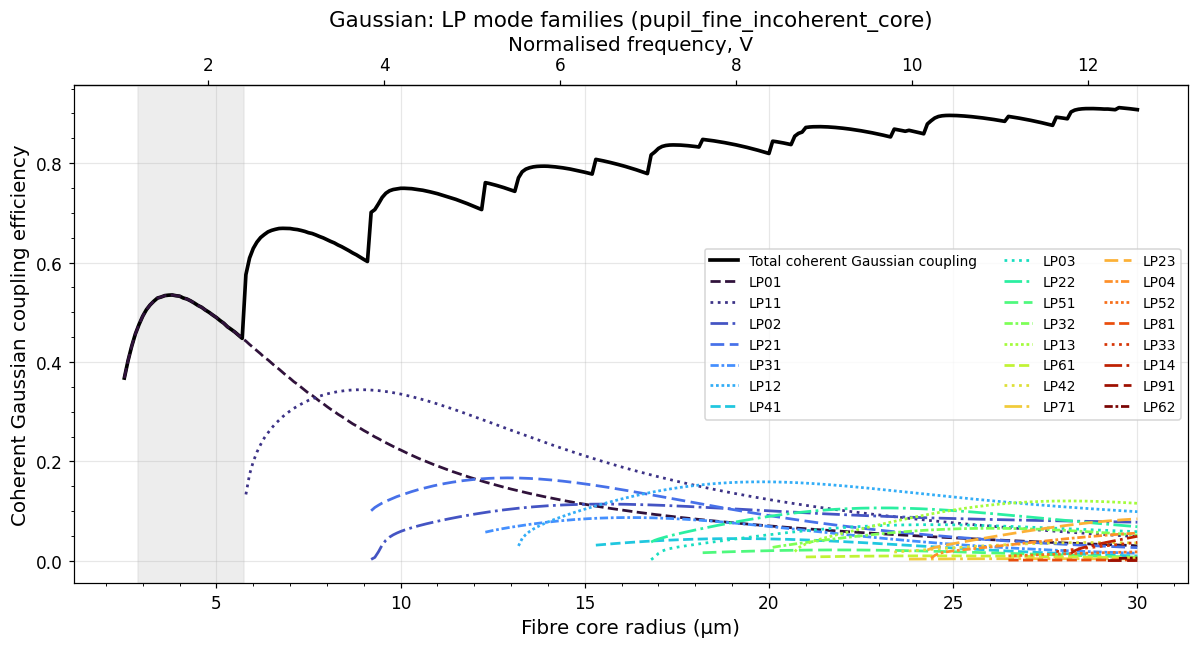

In [78]:
gaussian_incoherent_core_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=eta_gaussian_incoherent_core,
    results_by_radius=gaussian_incoherent_core_modes,
    lam0=lam0,
    NA=NA,
    method="pupil_fine_incoherent_core",
    source_name="Gaussian"
)

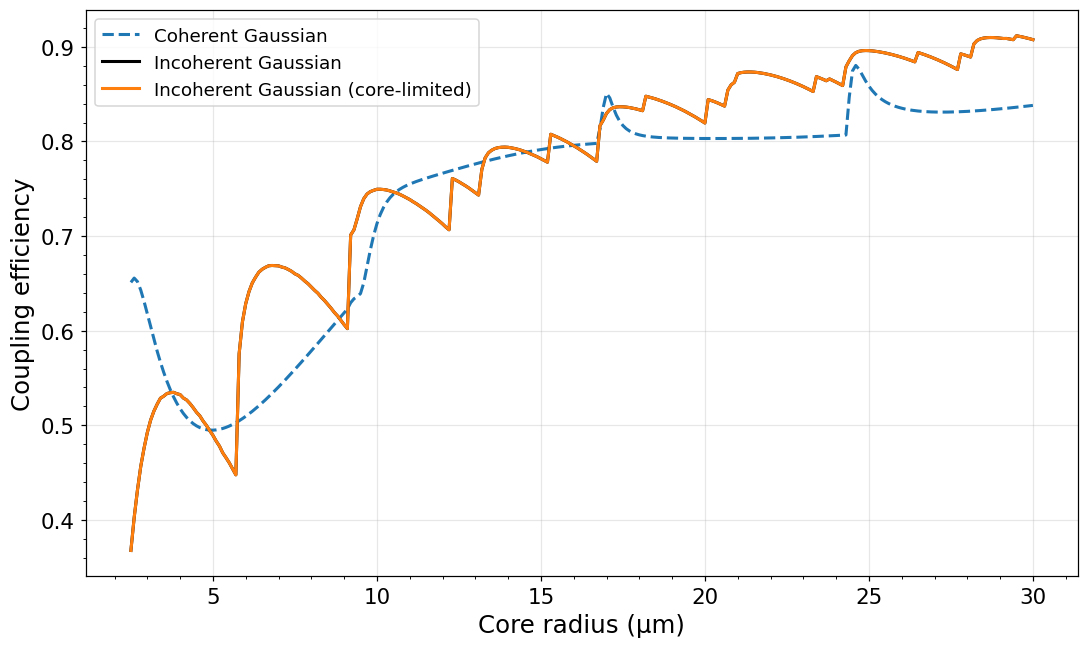

In [79]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    core_radius_range * 1e6,
    sweep["Gaussian"]["pupil_fine"],
    color="tab:blue",
    linestyle="--",
    linewidth=2,
    label="Coherent Gaussian"
)

ax.plot(
    core_radius_range * 1e6,
    sweep["Gaussian"]["pupil_fine_incoherent"],
    color="k",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Gaussian"
)

ax.plot(
    core_radius_range * 1e6,
    eta_gaussian_incoherent_core,
    color="tab:orange",
    # linestyle="--",
    linewidth=2,
    label="Incoherent Gaussian (core-limited)"
)

ax.set_xlabel("Core radius (µm)", fontsize=16)
ax.set_ylabel("Coupling efficiency", fontsize=16)

ax.tick_params(axis="both", labelsize=14)
ax.minorticks_on()
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

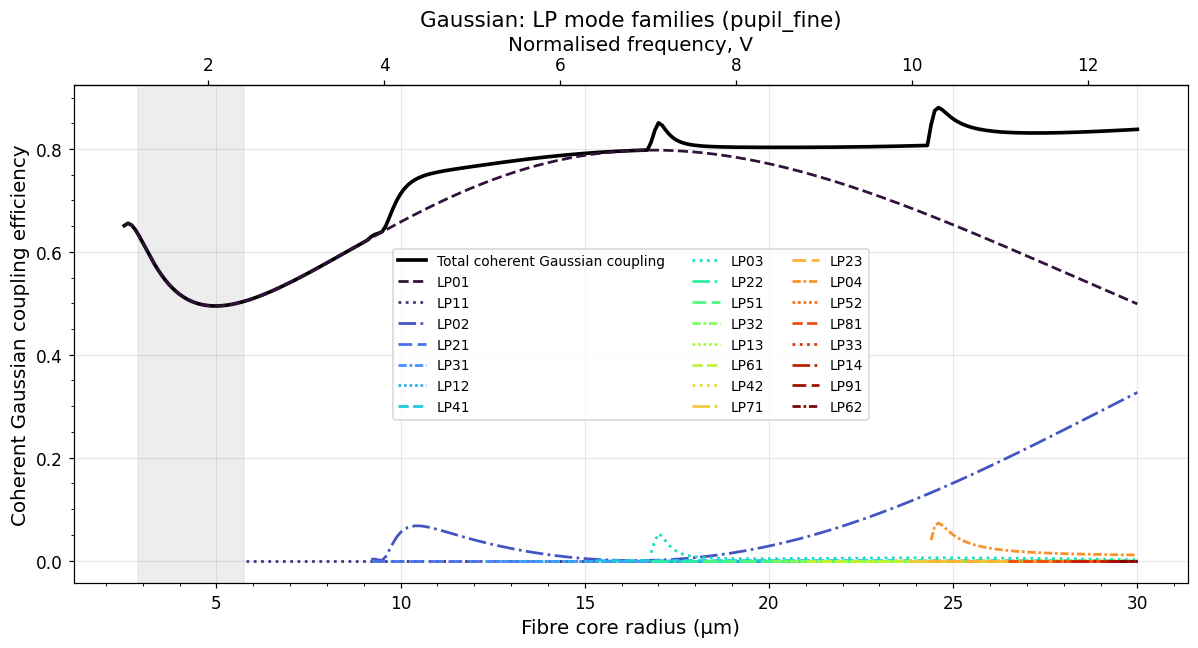

In [80]:
sersic_pupil_families = plot_coherent_lp_mode_families(
    core_radius_array=core_radius_range,
    total_eta=sweep["Gaussian"]["pupil_fine"],
    results_by_radius=mode_results_by_radius["Gaussian"],
    lam0=lam0,
    NA=NA,
    method="pupil_fine",
    source_name="Gaussian"
)

In [82]:
from IPython import get_ipython
import numpy as np
import pandas as pd

sizes = []

for name, value in list(get_ipython().user_ns.items()):
    if isinstance(value, (np.ndarray, pd.Series, pd.DataFrame)):
        sizes.append((name, value.nbytes / 1024**3))

for name, size_gb in sorted(sizes, key=lambda item: item[1], reverse=True):
    print(f"{name:<30} {size_gb:.3f} GB")

E_base_pupil                   0.015 GB
E_psf_fft                      0.015 GB
E_psf_analytic                 0.015 GB
E_periodic                     0.015 GB
E_linear                       0.015 GB
A                              0.015 GB
B                              0.015 GB
E_gal_focal                    0.015 GB
E_pupil_fft                    0.015 GB
E_conv_norm                    0.015 GB
E_pupil_norm                   0.015 GB
E_pupil_method                 0.015 GB
E_conv_method                  0.015 GB
E_conv_aligned                 0.015 GB
_                              0.007 GB
x                              0.007 GB
y                              0.007 GB
x_arcsec                       0.007 GB
y_arcsec                       0.007 GB
QX                             0.007 GB
QY                             0.007 GB
PX                             0.007 GB
PY                             0.007 GB
R_pupil                        0.007 GB
I_gaussian                     0.007 GB


In [84]:
for name, size_gb in sorted(sizes, key=lambda item: item[1], reverse=True):
    if size_gb >= 10 / 1024:
        print(f"{name:<30} {size_gb:.3f} GB")

E_base_pupil                   0.015 GB
E_psf_fft                      0.015 GB
E_psf_analytic                 0.015 GB
E_periodic                     0.015 GB
E_linear                       0.015 GB
A                              0.015 GB
B                              0.015 GB
E_gal_focal                    0.015 GB
E_pupil_fft                    0.015 GB
E_conv_norm                    0.015 GB
E_pupil_norm                   0.015 GB
E_pupil_method                 0.015 GB
E_conv_method                  0.015 GB
E_conv_aligned                 0.015 GB
